# Message-level perplexity: one loss number that survives a change of tokenizer

Everything in this repo reports **per-token** cross-entropy, and per-token CE cannot be
compared across tokenizations: the 22/23/24/26-token encodings cut the same LOBSTER
message into different numbers of tokens, so 0.60 nats per token under one encoding is
not 0.60 under another. Per **message** it is comparable, and exactly so: by the chain
rule the message NLL is the sum over that message's tokens, and for a lossless bijective
encoding that sum belongs to the message and the model, not to the encoding.

Two variants are reported.

* **`main`** (the headline) -- the message's own new content: event type, direction,
  price, size, inter-arrival time.
* **`full`** -- every token, including the reference fields that point at an order the
  book already contains.

Everything below reads records that live outside the repository: the per-position CE records
under `/lus/lfs1aip2/projects/public/u6gb/sigma-0/artifacts/ce_by_position/` (model-zoo records
that were never committed; the eleven under `docs/experiments/trainloss_profiling_20260826/data/`
are the committed subset), and the derived
report the reporter writes from them. Nothing here recomputes a model.

In [1]:
%matplotlib inline
import io, json, sys, math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display

# 300 dpi everywhere; the palette quantisation in show() is what keeps the
# notebook inside GitHub's inline-rendering budget at that resolution.
plt.rcParams.update({'figure.dpi': 300, 'savefig.dpi': 220})
# savefig.dpi, not figsize: font sizes are in points and do not scale with the
# figure, so shrinking figsize makes labels collide. 220 keeps the committed
# notebook inside GitHub's inline-render budget with three more figures in it.

REPO = Path.cwd().parents[1]
sys.path.insert(0, str(REPO / 'src'))
from lob.message_perplexity import message_perplexity, message_perplexity_from_per_field, classify_field

def show(fig):
    """Render at 300 dpi, then quantise to a 256-colour palette PNG.

    Flat-colour plots quantise losslessly to the eye. This lives inside the
    notebook on purpose: as a post-processing step the next
    `nbconvert --execute --inplace` would silently undo it."""
    buf = io.BytesIO(); fig.savefig(buf, format='png', bbox_inches='tight')
    plt.close(fig); buf.seek(0)
    try:
        from PIL import Image as PILImage
        im = PILImage.open(buf).convert('RGB').quantize(colors=256, method=2)
        out = io.BytesIO(); im.save(out, format='PNG', optimize=True)
        display(Image(data=out.getvalue()))
    except ImportError:
        display(Image(data=buf.getvalue()))

ROLE_COLOR = {'main': '#2b6cb0', 'absolute_time': '#a0aec0', 'reference': '#dd6b20'}
ROLE_LABEL = {'main': 'main (scored by both variants)',
              'absolute_time': 'absolute time (redundant duplicate)',
              'reference': 'reference fields (points at a prior order)'}

records = {}
for path in sorted((REPO / 'artifacts' / 'ce_by_position').glob('*.json')):
    rec = json.loads(path.read_text())
    records[rec['slice']['label']] = rec
report = json.loads((REPO / 'artifacts' / 'message_perplexity' / 'report.json').read_text())
by_slice = {e['slice_label']: e for e in report['entries']}

print('records:', {k: f"{v['slice']['messages']} messages" for k, v in records.items()})
print('checkpoint:', records['heldout']['checkpoint']['root'].split('/')[-1],
      'step', records['heldout']['checkpoint']['step'])

records: {'train_period': '32000 messages', 'heldout': '32000 messages', 'heldout_v2': '64000 messages', 'samemonth_leakfree': '28000 messages', 'samemonth_trained': '28000 messages', 'train_period_v2': '64000 messages', 'valset_2022': '64000 messages', 'valset_2023': '48000 messages', 'valset_2024': '64000 messages', 'valset_2025': '64000 messages', 'valset_2025h1': '32000 messages', 'valset_2025h2': '32000 messages', 'valset_all': '256000 messages', 'y2022': '32000 messages', 'y2022h2': '32000 messages', 'y2022h3': '32000 messages', 'y2023': '32000 messages', 'y2023h2': '32000 messages', 'y2023h3': '32000 messages', 'y2024': '32000 messages', 'y2024h2': '32000 messages', 'y2024h3': '32000 messages', 'y2025': '32000 messages', 'y2025h2': '32000 messages', 'y2025h3': '32000 messages', 'tkAAPL': '32000 messages', 'tkAMD': '32000 messages', 'tkAMZN': '32000 messages', 'tkCVX': '32000 messages', 'tkGOOGL': '32000 messages', 'tkHD': '32000 messages', 'tkINTC': '32000 messages', 'tkJNJ': '3

## Figure 1 - the definition, drawn

One message, under each encoding, coloured by the role of each token. The token counts
differ; the roles do not.

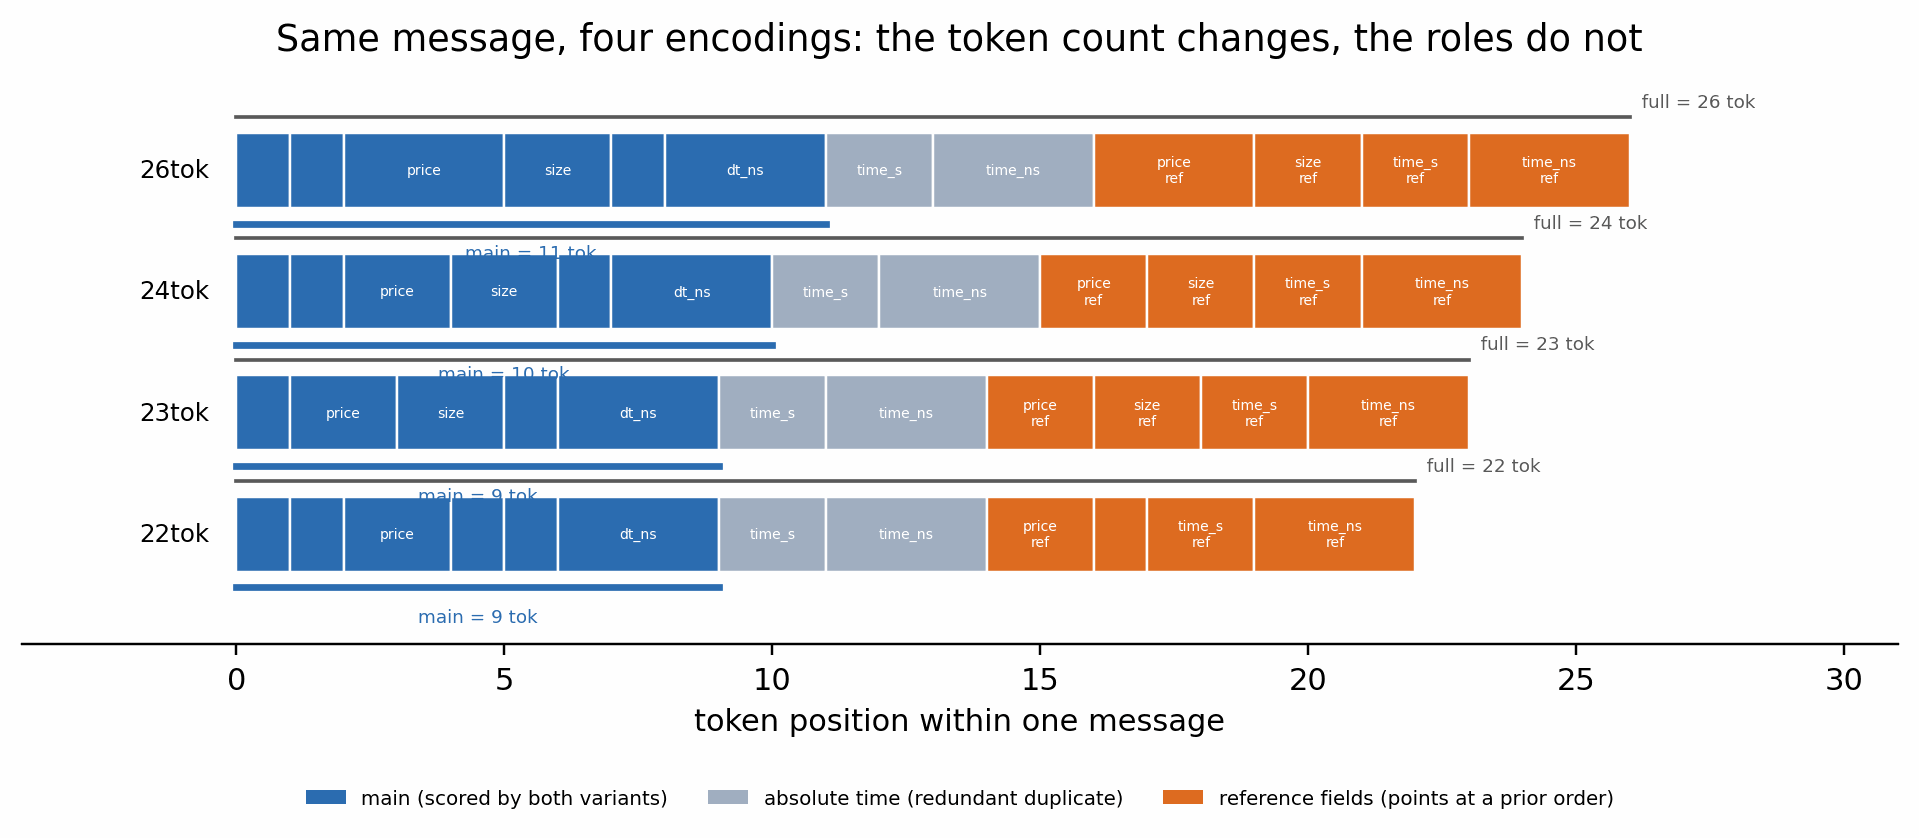

In [2]:
import ast
def widths(mode):
    src = (REPO / 'src' / 'lob' / f'encoding_{mode}.py').read_text()
    tree = ast.parse(src); f = w = None
    for node in ast.walk(tree):
        if isinstance(node, ast.ClassDef) and node.name == 'Message_Tokenizer':
            for st in node.body:
                if isinstance(st, ast.Assign) and isinstance(st.targets[0], ast.Name):
                    if st.targets[0].id == 'FIELDS':
                        f = list(ast.literal_eval(st.value))
                    elif st.targets[0].id == 'TOK_LENS':
                        v = st.value
                        if isinstance(v, ast.Call) and v.args: v = v.args[0]
                        w = [int(x) for x in ast.literal_eval(v)]
    return dict(zip(f, w))

MODES = ['22tok', '23tok', '24tok', '26tok']
fig, ax = plt.subplots(figsize=(11, 3.4))
for row, mode in enumerate(MODES):
    wd = widths(mode); x = 0
    for name, n in wd.items():
        role = classify_field(name)
        ax.add_patch(Rectangle((x, row), n, 0.62, facecolor=ROLE_COLOR[role],
                               edgecolor='white', linewidth=0.8))
        if n >= 2:
            ax.text(x + n / 2, row + 0.31, name.replace('_ref', '\nref').replace('delta_t_', 'dt_'),
                    ha='center', va='center', fontsize=4.6, color='white')
        x += n
    ax.text(-0.5, row + 0.31, mode, ha='right', va='center', fontsize=8)
    main_n = sum(n for f, n in wd.items() if classify_field(f) == 'main')
    ax.plot([0, main_n], [row - 0.13, row - 0.13], color=ROLE_COLOR['main'], lw=2.2)
    ax.text(main_n / 2, row - 0.30, f'main = {main_n} tok', ha='center', va='top',
            fontsize=6, color=ROLE_COLOR['main'])
    ax.plot([0, x], [row + 0.75, row + 0.75], color='0.35', lw=1.2)
    ax.text(x, row + 0.80, f'  full = {x} tok', ha='left', va='bottom', fontsize=6, color='0.35')
ax.set_xlim(-4, 31); ax.set_ylim(-0.6, len(MODES) + 0.15)
ax.set_xlabel('token position within one message'); ax.set_yticks([])
for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
handles = [Rectangle((0, 0), 1, 1, facecolor=ROLE_COLOR[r]) for r in ROLE_COLOR]
ax.legend(handles, [ROLE_LABEL[r] for r in ROLE_COLOR], fontsize=6.5, ncol=3,
          loc='upper center', bbox_to_anchor=(0.5, -0.22), frameon=False)
ax.set_title('Same message, four encodings: the token count changes, the roles do not')
show(fig)

*The `main` variant scores the message's own content and stops before the reference
fields. It is the absolute price and the absolute timestamp despite scoring relative
representations, because both references are fixed by the past: the price is quoted
against the previous mid-price, the timestamp is the previous one plus `delta_t`. The
absolute-time tokens are the deterministic duplicate of `delta_t` and are excluded so
each field is paid for once.*

## Figure 2 - where a message's uncertainty actually sits

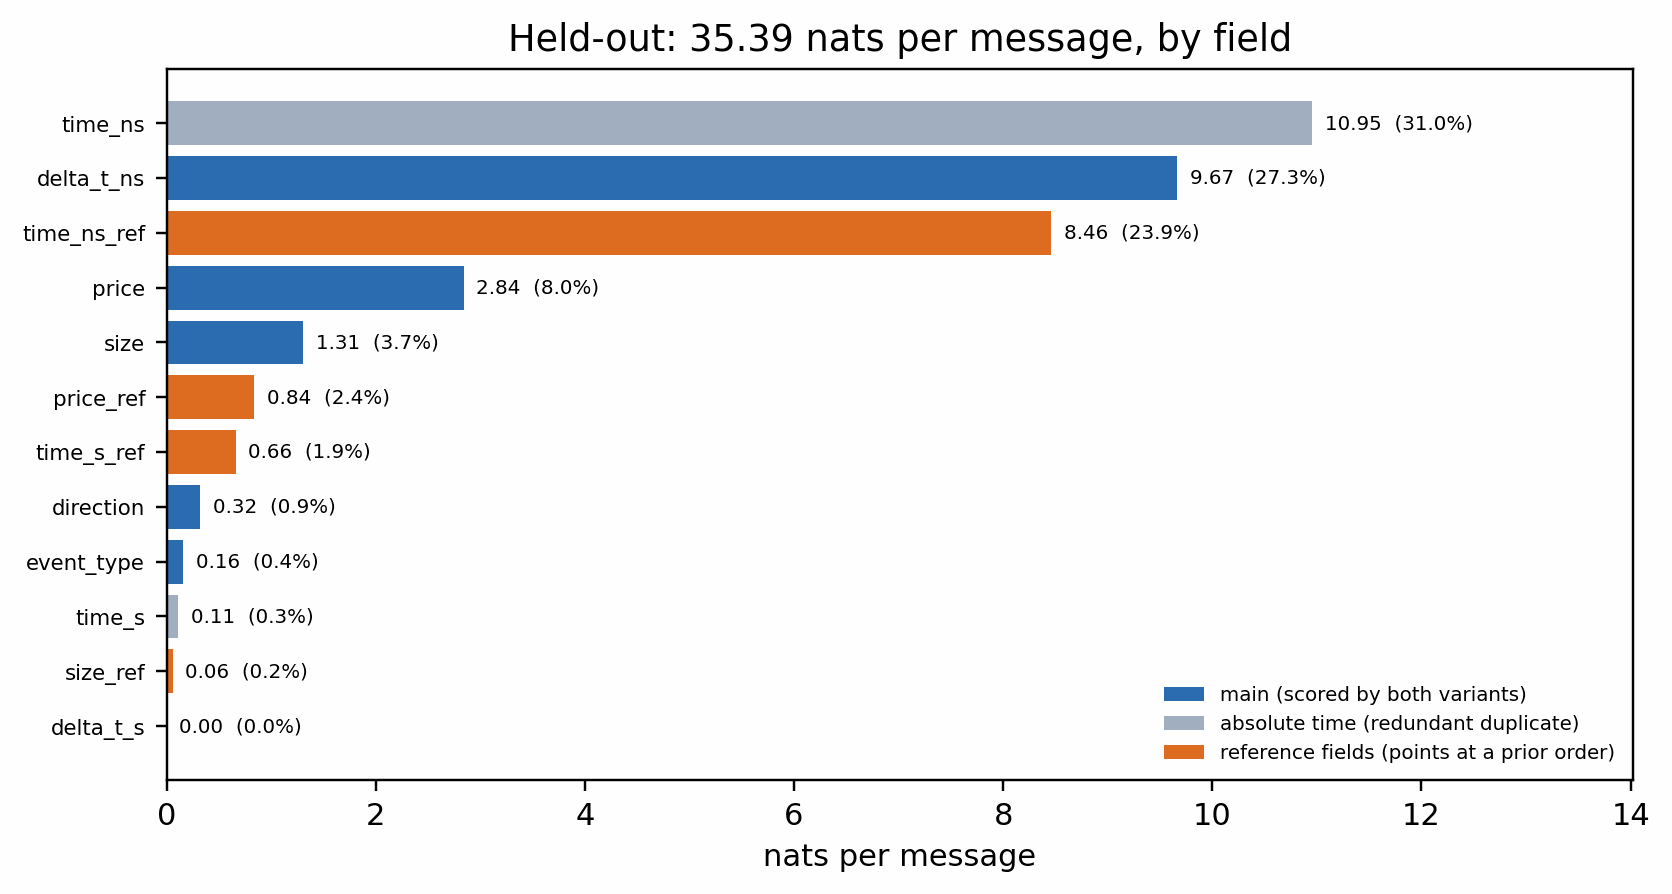

In [3]:
rec = records['heldout']
rows = [(r['field'], r['ce'] * r['width'], r['width']) for r in rec['per_field']]
rows.sort(key=lambda t: -t[1])
total = sum(v for _, v, _ in rows)

fig, ax = plt.subplots(figsize=(8.6, 4.2))
names = [n for n, _, _ in rows]; vals = [v for _, v, _ in rows]
colors = [ROLE_COLOR[classify_field(n)] for n in names]
bars = ax.barh(range(len(names))[::-1], vals, color=colors)
for i, (n, v, w) in enumerate(rows):
    ax.text(v + 0.12, len(names) - 1 - i, f'{v:.2f}  ({100*v/total:.1f}%)',
            va='center', fontsize=6.5)
ax.set_yticks(range(len(names))[::-1], names, fontsize=7)
ax.set_xlabel('nats per message'); ax.set_xlim(0, max(vals) * 1.28)
ax.set_title(f'Held-out: {total:.2f} nats per message, by field')
handles = [Rectangle((0, 0), 1, 1, facecolor=ROLE_COLOR[r]) for r in ROLE_COLOR]
ax.legend(handles, [ROLE_LABEL[r] for r in ROLE_COLOR], fontsize=6.5, loc='lower right', frameon=False)
show(fig)

*Two fields carry three quarters of the message: the nanosecond inter-arrival time
(9.72 nats, 47%) and the nanosecond part of the **reference** timestamp (5.35 nats, 26%).
The second one is the model recalling which resting order is being touched, not modelling
a new market event -- which is exactly why the two variants need separating.*

## Figure 3 - the two variants and the decomposition between them

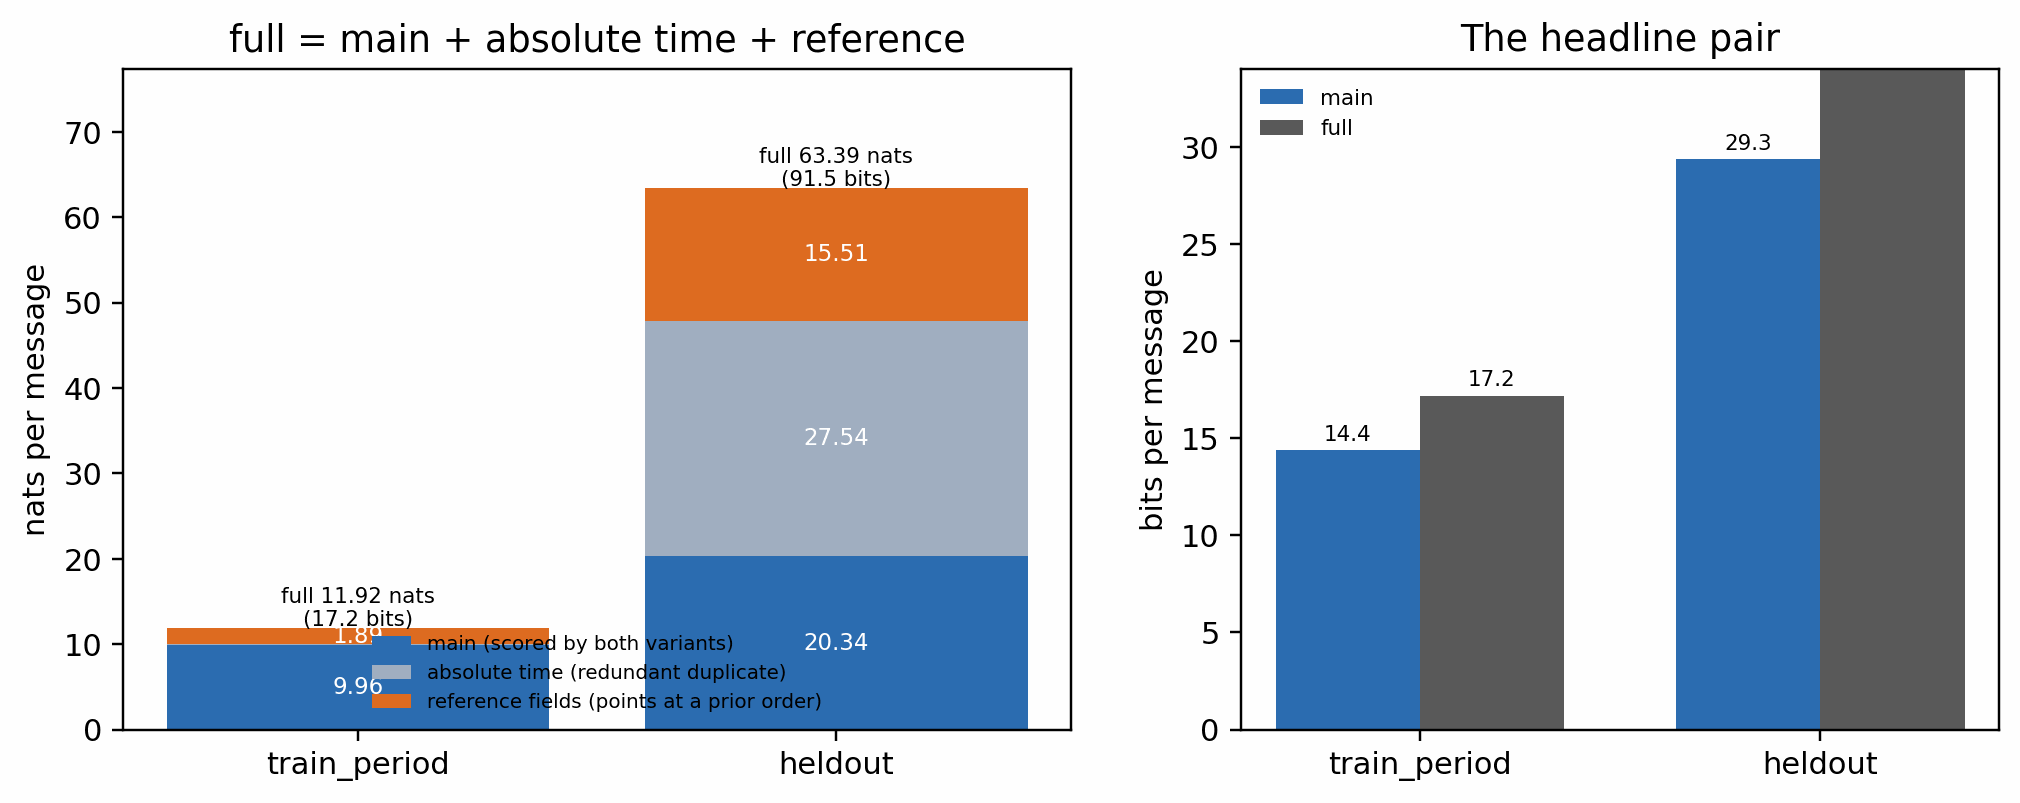

In [4]:
labels = ['train_period', 'heldout']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={'width_ratios': [1.25, 1]})

ax = axes[0]; bottom = np.zeros(len(labels))
for role in ('main', 'absolute_time', 'reference'):
    vals = np.array([by_slice[l]['components_nats_per_message'][role] for l in labels])
    ax.bar(labels, vals, bottom=bottom, color=ROLE_COLOR[role], label=ROLE_LABEL[role])
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 0.6:
            ax.text(i, b + v / 2, f'{v:.2f}', ha='center', va='center',
                    fontsize=7.5, color='white')
    bottom += vals
for i, l in enumerate(labels):
    ax.text(i, bottom[i] + 0.25, f"full {bottom[i]:.2f} nats\n({bottom[i]/math.log(2):.1f} bits)",
            ha='center', fontsize=7)
ax.set_ylabel('nats per message'); ax.set_ylim(0, bottom.max() * 1.22)
ax.legend(fontsize=6.5, loc='lower center', frameon=False)
ax.set_title('full = main + absolute time + reference')

ax = axes[1]
x = np.arange(len(labels)); w = 0.36
for k, (variant, col) in enumerate((('main', ROLE_COLOR['main']), ('full', '0.35'))):
    vals = [by_slice[l]['variants'][variant]['bits_per_message'] for l in labels]
    b = ax.bar(x + (k - 0.5) * w, vals, w, color=col, label=variant)
    ax.bar_label(b, fmt='%.1f', fontsize=7, padding=2)
ax.set_xticks(x, labels); ax.set_ylabel('bits per message')
ax.legend(fontsize=7, frameon=False); ax.set_ylim(0, 34)
ax.set_title('The headline pair')
show(fig)

*The reference fields are 30.1% of the held-out message NLL and 29.7% of the
train-period one. A ranking built on `full` is therefore three-tenths a ranking of how
well a model recalls the book's existing orders; `main` is the part about the new event.*

## Figure 4 - the same evidence, per token: why the denominator matters

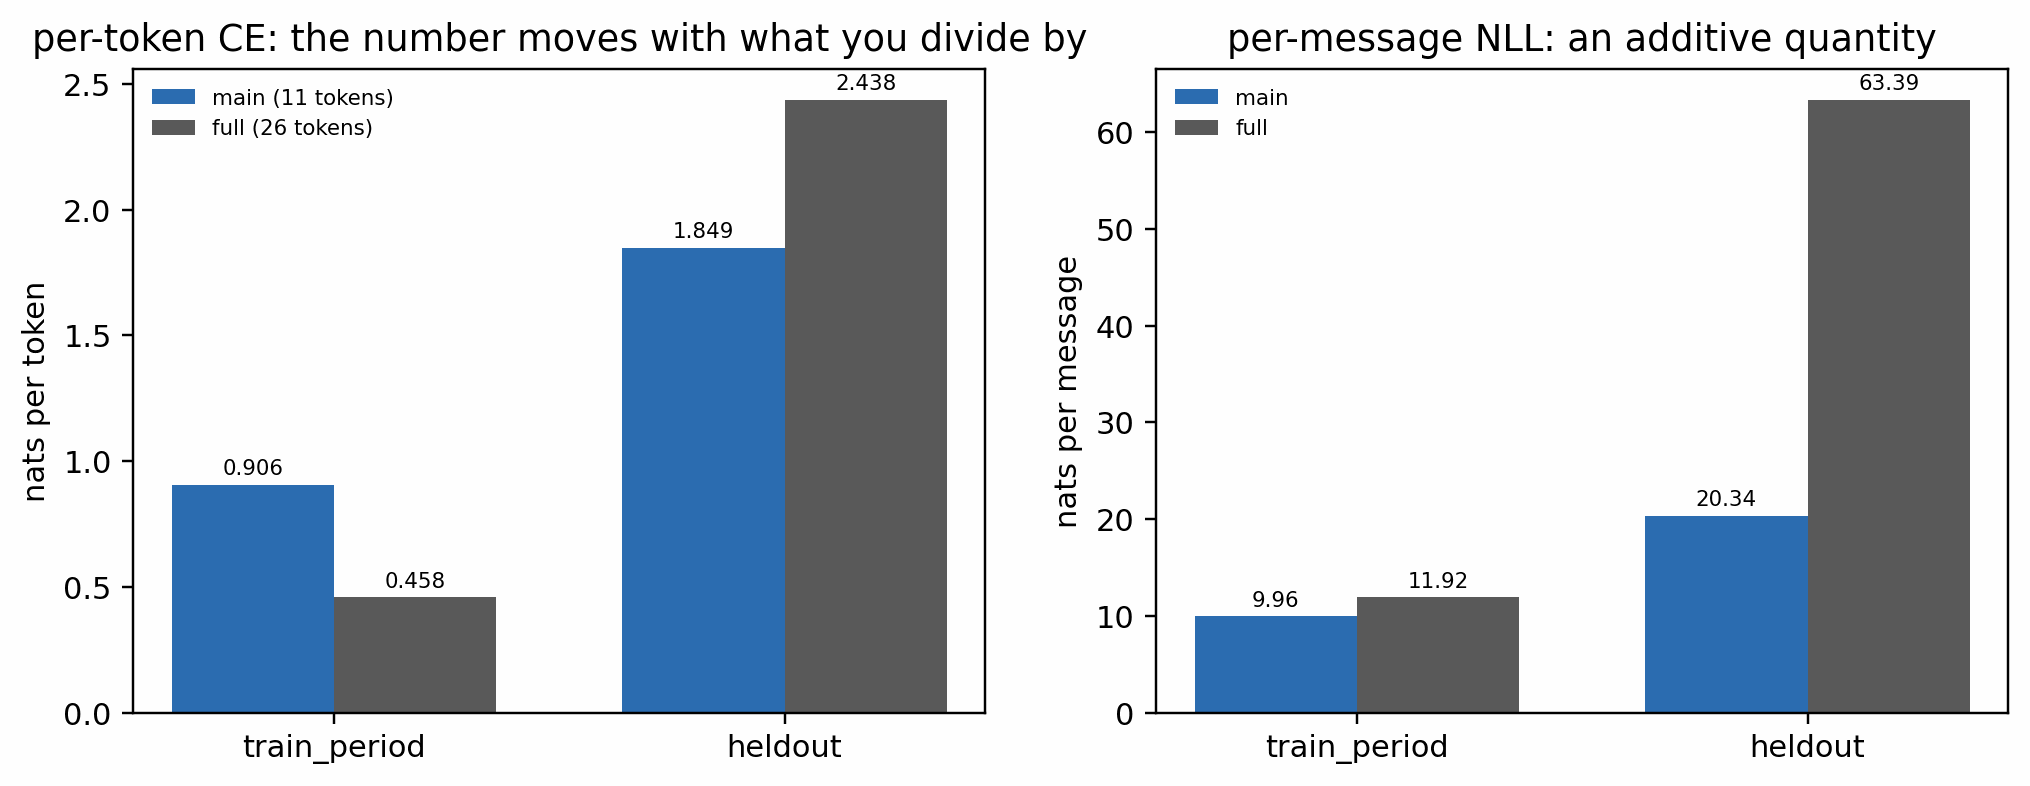

train_period: per-token main 0.9056 vs full 0.4584  -> ratio 1.98x from the denominator alone
heldout: per-token main 1.8493 vs full 2.4382  -> ratio 0.76x from the denominator alone


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
scored = {'main': 11, 'full': 26}
ax = axes[0]
x = np.arange(len(labels)); w = 0.36
for k, (variant, col) in enumerate((('main', ROLE_COLOR['main']), ('full', '0.35'))):
    vals = [by_slice[l]['variants'][variant]['nats_per_message'] / scored[variant] for l in labels]
    b = ax.bar(x + (k - 0.5) * w, vals, w, color=col,
               label=f'{variant} ({scored[variant]} tokens)')
    ax.bar_label(b, fmt='%.3f', fontsize=7, padding=2)
ax.set_xticks(x, labels); ax.set_ylabel('nats per token')
ax.legend(fontsize=7, frameon=False)
ax.set_title('per-token CE: the number moves with what you divide by')

ax = axes[1]
for k, (variant, col) in enumerate((('main', ROLE_COLOR['main']), ('full', '0.35'))):
    vals = [by_slice[l]['variants'][variant]['nats_per_message'] for l in labels]
    b = ax.bar(x + (k - 0.5) * w, vals, w, color=col, label=variant)
    ax.bar_label(b, fmt='%.2f', fontsize=7, padding=2)
ax.set_xticks(x, labels); ax.set_ylabel('nats per message')
ax.legend(fontsize=7, frameon=False)
ax.set_title('per-message NLL: an additive quantity')
show(fig)

for l in labels:
    m = by_slice[l]['variants']['main']['nats_per_message'] / 11
    f = by_slice[l]['variants']['full']['nats_per_message'] / 26
    print(f'{l}: per-token main {m:.4f} vs full {f:.4f}  -> ratio {m/f:.2f}x '
          f'from the denominator alone')

*The two per-token numbers on the left differ by a factor of 1.6 on the very same
evidence, purely through the choice of denominator. On the right the quantity is additive,
so nothing about it depends on how the message was cut up.*

## Figure 5 - the invariance, demonstrated

The same message content, spread across whatever fields each encoding happens to use.
A tokenization-invariant metric must return one number; per-token CE cannot.

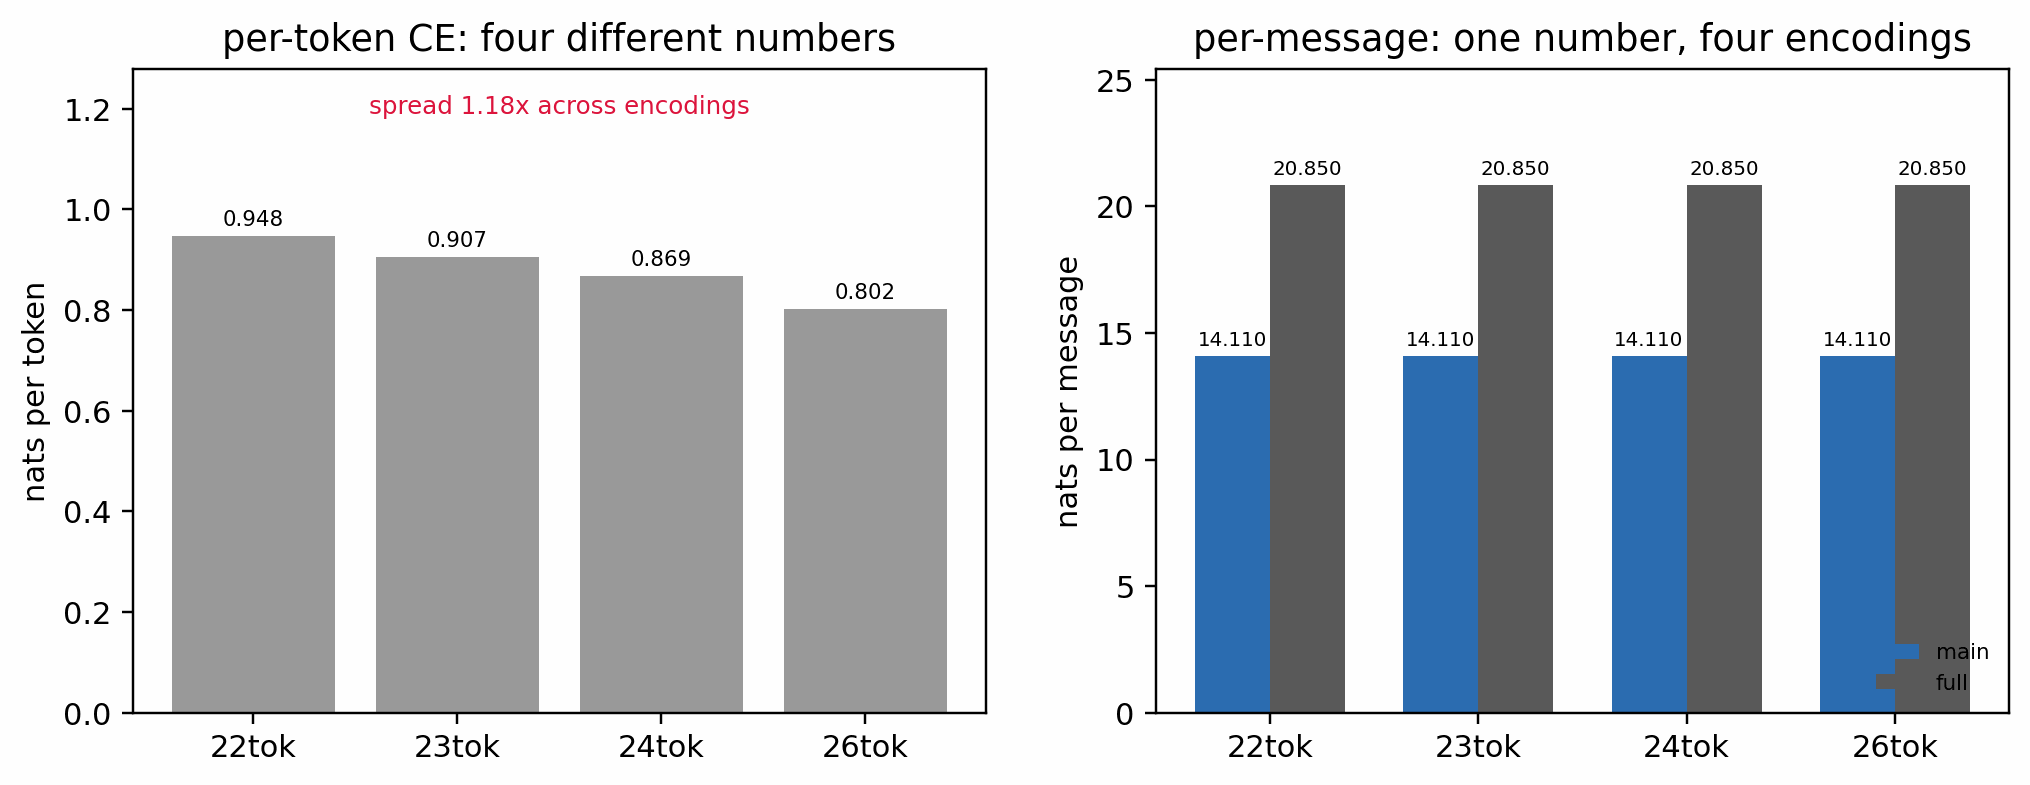

main nats by encoding: {'22tok': 14.11, '23tok': 14.11, '24tok': 14.11, '26tok': 14.11}
full nats by encoding: {'22tok': 20.85, '23tok': 20.85, '24tok': 20.85, '26tok': 20.85}
token counts        : {'22tok': 22, '23tok': 23, '24tok': 24, '26tok': 26}


In [6]:
budget = {'event': 1.10, 'price': 2.25, 'size': 1.04,
          'delta_t': 9.72, 'abs_time': 0.47, 'reference': 6.27}

def synthetic(mode):
    wd = widths(mode); table = {}
    def spread(total, names):
        wts = [i + 1 for i in range(len(names))]
        for n, w in zip(names, wts):
            table[n] = total * w / sum(wts)
    fields = list(wd)
    spread(budget['event'], [f for f in fields if f in ('event_type', 'direction', 'event_dir')])
    spread(budget['price'], ['price']); spread(budget['size'], ['size'])
    spread(budget['delta_t'], [f for f in fields if f.startswith('delta_t')])
    spread(budget['abs_time'], [f for f in fields if f in ('time_s', 'time_ns')])
    spread(budget['reference'], [f for f in fields if f.endswith('_ref')])
    return table, wd

res = {}
for mode in MODES:
    table, wd = synthetic(mode)
    res[mode] = message_perplexity(table, token_mode=mode, field_widths=wd)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
per_tok = [res[m].full_nats / res[m].n_tokens['full'] for m in MODES]
b = ax.bar(MODES, per_tok, color='0.6'); ax.bar_label(b, fmt='%.3f', fontsize=7, padding=2)
ax.set_ylabel('nats per token'); ax.set_title('per-token CE: four different numbers')
ax.set_ylim(0, max(per_tok) * 1.35)
ax.text(0.5, 0.93, f'spread {max(per_tok)/min(per_tok):.2f}x across encodings',
        transform=ax.transAxes, ha='center', fontsize=8, color='crimson')

ax = axes[1]
x = np.arange(len(MODES)); w = 0.36
for k, (key, col) in enumerate((('main', ROLE_COLOR['main']), ('full', '0.35'))):
    vals = [res[m].main_nats if key == 'main' else res[m].full_nats for m in MODES]
    b = ax.bar(x + (k - 0.5) * w, vals, w, color=col, label=key)
    ax.bar_label(b, fmt='%.3f', fontsize=6.5, padding=2)
ax.set_xticks(x, MODES); ax.set_ylabel('nats per message')
ax.set_ylim(0, max(res[m].full_nats for m in MODES) * 1.22)
ax.legend(fontsize=7, frameon=False, loc='lower right')
ax.set_title('per-message: one number, four encodings')
show(fig)

print('main nats by encoding:', {m: round(res[m].main_nats, 9) for m in MODES})
print('full nats by encoding:', {m: round(res[m].full_nats, 9) for m in MODES})
print('token counts        :', {m: res[m].n_tokens['full'] for m in MODES})

*Left: the same message content reported as per-token CE gives four different answers,
because the four encodings divide by 22, 23, 24 and 26. Right: per message it is one
number to nine decimal places. This is the unit test `test_the_metric_is_invariant_across_tokenizations`
drawn; it runs on every CI push.*

## Figure 6 - which part of a message fails to generalise

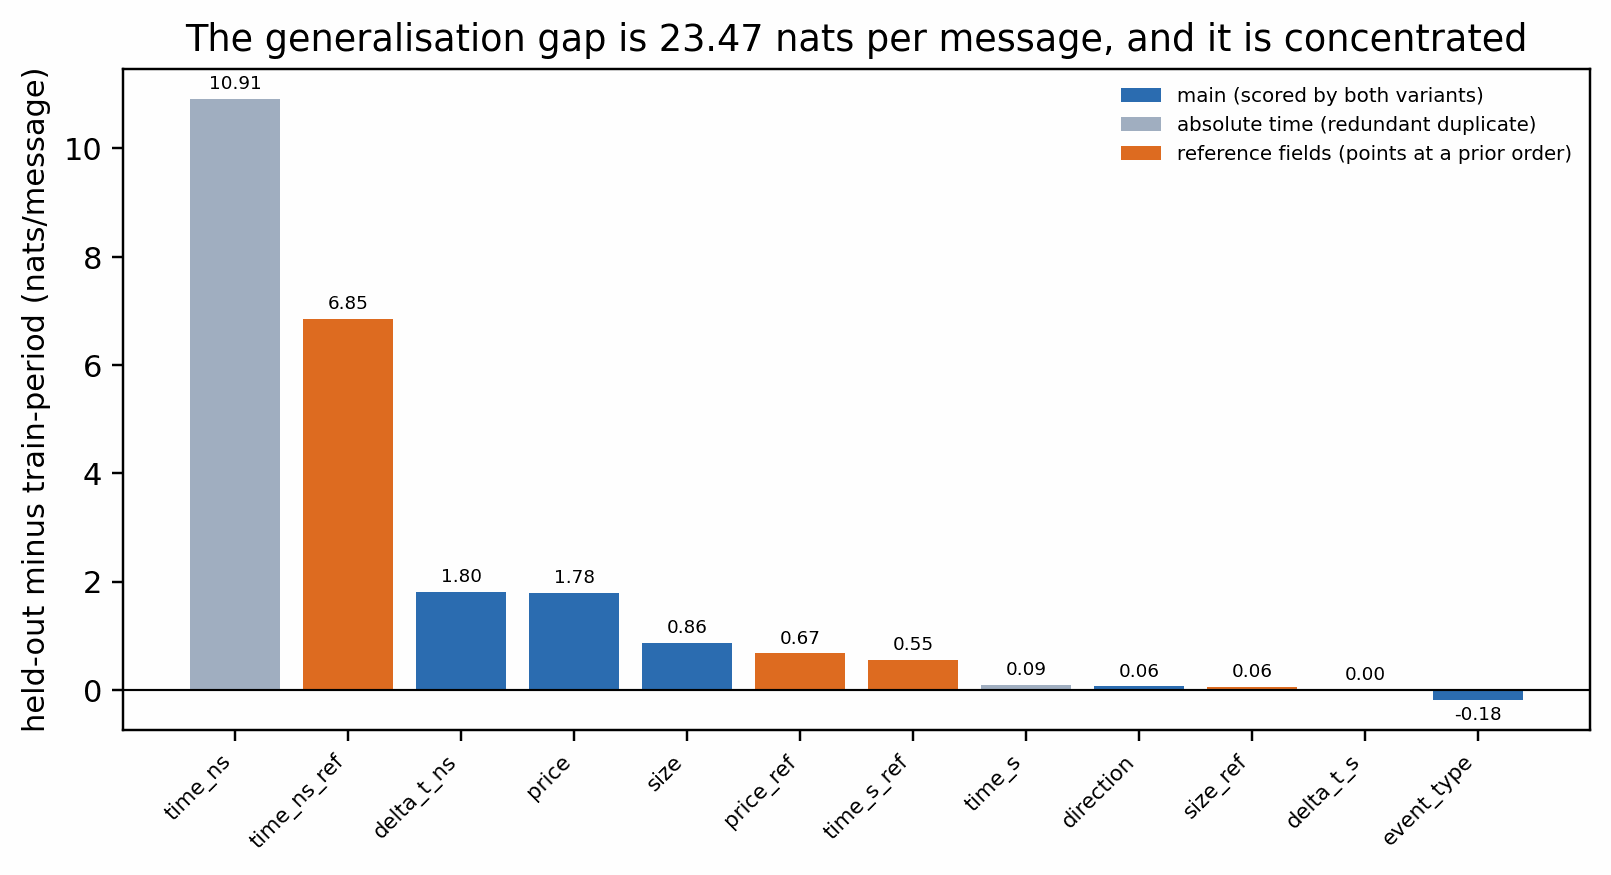

total gap 23.468 nats/msg  =  main 4.337 + reference 8.125 + absolute time 11.005
main carries 18% of the gap while being 32% of the loss


In [7]:
tr = {r['field']: r['ce'] * r['width'] for r in records['train_period']['per_field']}
ho = {r['field']: r['ce'] * r['width'] for r in records['heldout']['per_field']}
fields = sorted(ho, key=lambda f: -(ho[f] - tr[f]))
gap = [ho[f] - tr[f] for f in fields]

fig, ax = plt.subplots(figsize=(8.6, 3.9))
bars = ax.bar(range(len(fields)), gap,
              color=[ROLE_COLOR[classify_field(f)] for f in fields])
ax.bar_label(bars, fmt='%.2f', fontsize=6, padding=2)
ax.axhline(0, color='k', lw=0.7)
ax.set_xticks(range(len(fields)), fields, rotation=45, ha='right', fontsize=7)
ax.set_ylabel('held-out minus train-period (nats/message)')
tot = sum(gap)
ax.set_title(f'The generalisation gap is {tot:.2f} nats per message, and it is concentrated')
handles = [Rectangle((0, 0), 1, 1, facecolor=ROLE_COLOR[r]) for r in ROLE_COLOR]
ax.legend(handles, [ROLE_LABEL[r] for r in ROLE_COLOR], fontsize=6.5, frameon=False)
show(fig)

main_gap = sum(g for f, g in zip(fields, gap) if classify_field(f) == 'main')
ref_gap = sum(g for f, g in zip(fields, gap) if classify_field(f) == 'reference')
print(f'total gap {tot:.3f} nats/msg  =  main {main_gap:.3f} + reference {ref_gap:.3f} '
      f'+ absolute time {tot - main_gap - ref_gap:.3f}')
print(f'main carries {100*main_gap/tot:.0f}% of the gap while being '
      f"{100*by_slice['heldout']['components_nats_per_message']['main']/by_slice['heldout']['variants']['full']['nats_per_message']:.0f}% of the loss")

*The gap is not spread evenly: the inter-arrival nanoseconds and the reference timestamp
carry almost all of it. Reporting a single per-token mean hides this entirely, which was
the finding the per-position decomposition was built for.*

## Figure 7 - across the model ladder: the two variants are not the same curve

Every pinned 26-token model in the zoo, on the same held-out month.

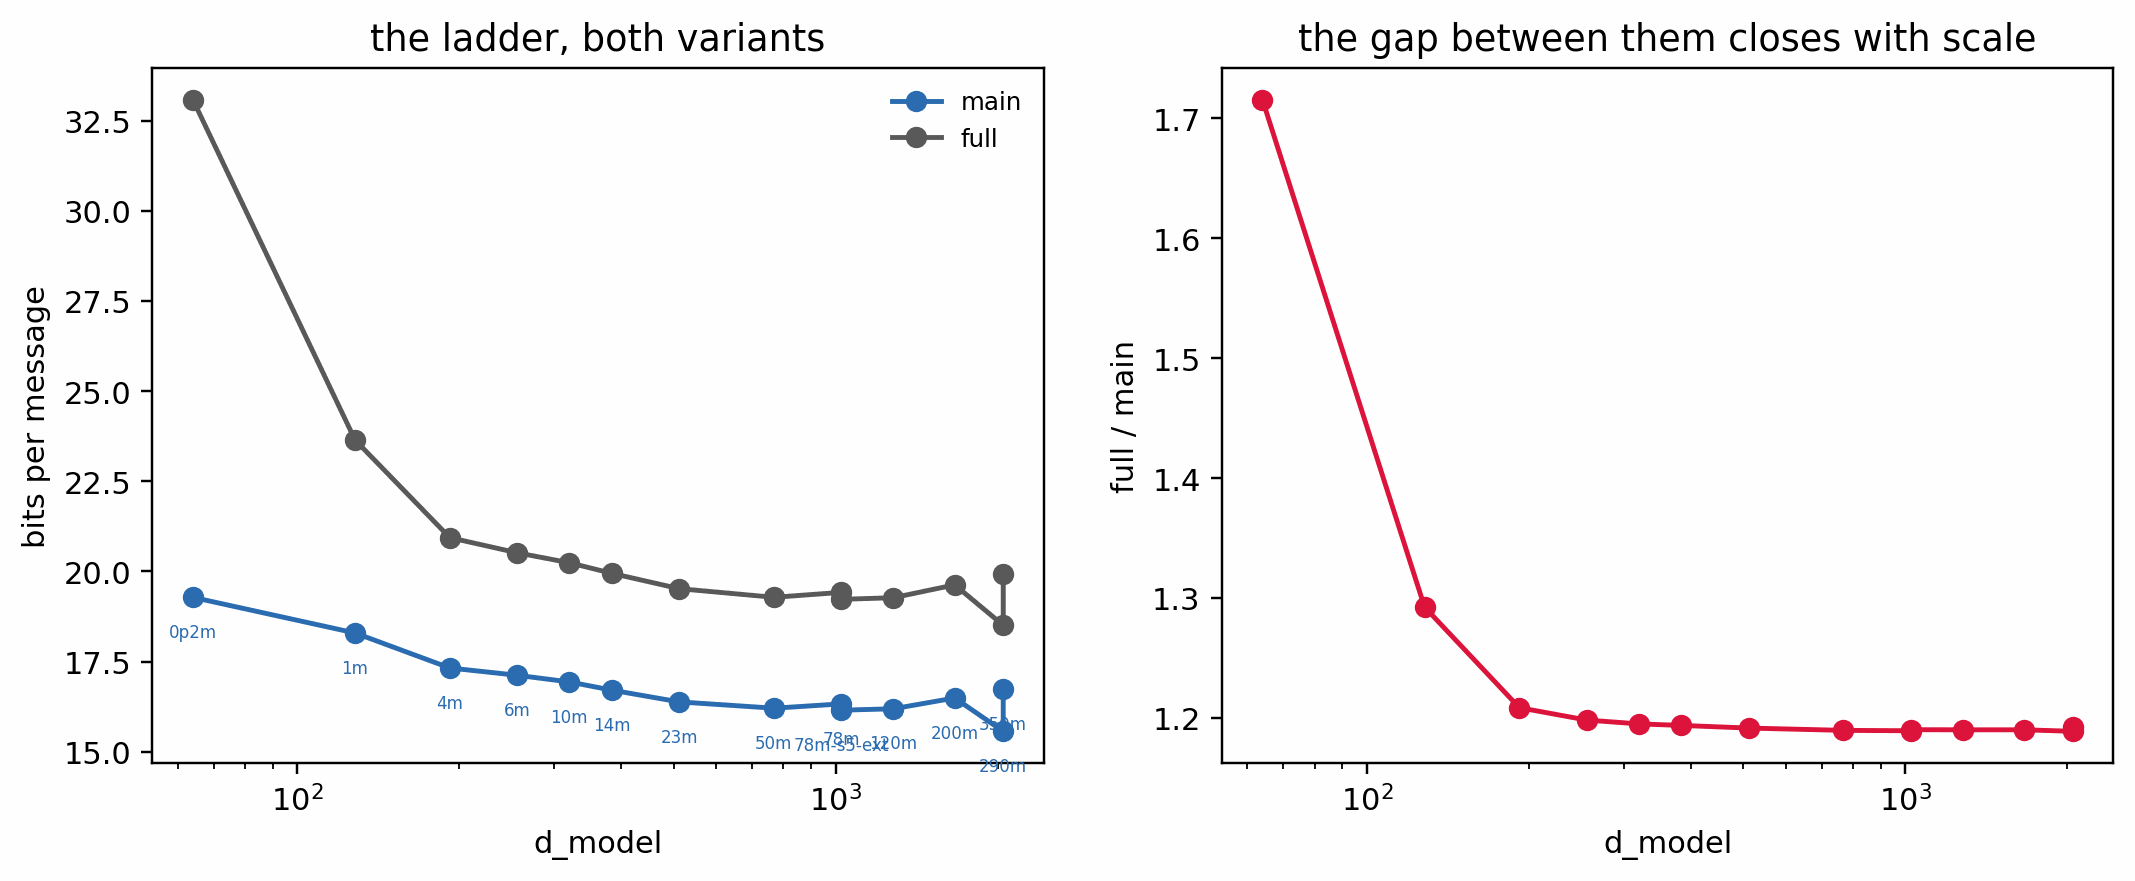

model          d  main bits  full bits   ref % per-tok CE
0p2m          64     19.282     33.073    29.5     0.8817
1m           128     18.295     23.646    21.6     0.6304
4m           192     17.325     20.938    16.8     0.5582
6m           256     17.124     20.518    16.1     0.5470
10m          320     16.939     20.242    15.9     0.5397
14m          384     16.710     19.948    15.8     0.5318
23m          512     16.385     19.524    15.6     0.5205
50m          768     16.210     19.284    15.5     0.5141
78m         1024     16.329     19.421    15.5     0.5178
78m-s5-ext  1024     16.155     19.228    15.5     0.5126
120m        1280     16.194     19.273    15.5     0.5138
200m        1664     16.493     19.629    15.5     0.5233
290m        2048     15.569     18.509    15.4     0.4935
350m        2048     16.729     19.943    15.7     0.5317


In [8]:
import glob, re
lad = []
for f in sorted(glob.glob(str(REPO / 'artifacts' / 'ce_by_position' / 'm3-sp500-*_heldout.json'))):
    d = json.loads(Path(f).read_text())
    mp = message_perplexity_from_per_field(d['per_field'], token_mode='26tok',
                                           n_messages=d['slice']['messages'])
    lad.append(dict(name=Path(f).name.replace('_heldout.json', '')
                         .replace('m3-sp500-', '').replace('-s42', ''),
                    d_model=d['checkpoint']['d_model'], step=d['checkpoint']['step'],
                    main=mp.main_nats, full=mp.full_nats,
                    ref=mp.components['reference'], per_tok=d['aggregate']['ce']))
lad.sort(key=lambda r: r['d_model'])
Ns = np.array([r['d_model'] for r in lad])
L2 = math.log(2)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1))
ax = axes[0]
for key, col in (('main', ROLE_COLOR['main']), ('full', '0.35')):
    ax.plot(Ns, [r[key] / L2 for r in lad], 'o-', color=col, lw=1.6, ms=6, label=key)
for r in lad:
    ax.annotate(r['name'], (r['d_model'], r['main'] / L2), xytext=(0, -13),
                textcoords='offset points', ha='center', fontsize=5.5,
                color=ROLE_COLOR['main'])
ax.set_xscale('log'); ax.set_xlabel('d_model'); ax.set_ylabel('bits per message')
ax.legend(fontsize=8, frameon=False); ax.set_title('the ladder, both variants')

ax = axes[1]
ax.plot(Ns, [r['full'] / r['main'] for r in lad], 'o-', color='crimson', lw=1.6, ms=6)
ax.set_xscale('log'); ax.set_xlabel('d_model'); ax.set_ylabel('full / main')
ax.set_title('the gap between them closes with scale')
show(fig)

print(f"{'model':<10}{'d':>6}{'main bits':>11}{'full bits':>11}{'ref %':>8}{'per-tok CE':>11}")
for r in lad:
    print(f"{r['name']:<10}{r['d_model']:>6}{r['main']/L2:>11.3f}{r['full']/L2:>11.3f}"
          f"{100*r['ref']/r['full']:>8.1f}{r['per_tok']:>11.4f}")

*The two variants do not trace the same scaling curve: `full` falls much faster than
`main` at the small end. A ranking or a scaling-law fit built on one is therefore not the
same exercise as one built on the other, which the single-model version of this notebook
could not show.*

## Figure 8 - what the reference fields cost, by scale

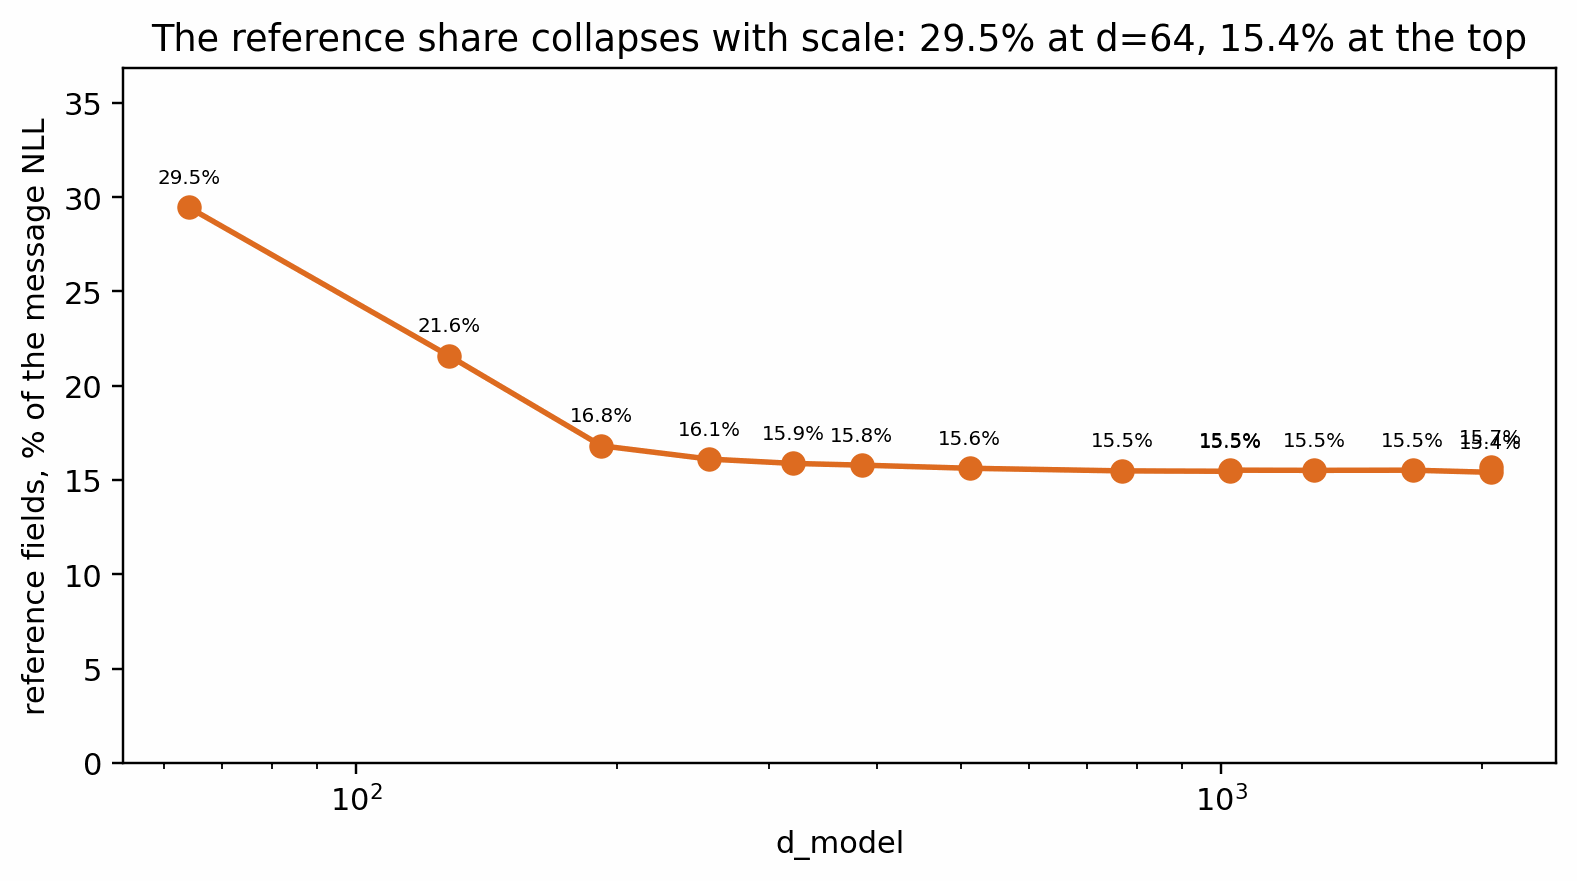

In [9]:
fig, ax = plt.subplots(figsize=(8.4, 4.1))
share = np.array([100 * r['ref'] / r['full'] for r in lad])
ax.plot(Ns, share, 'o-', color=ROLE_COLOR['reference'], lw=1.8, ms=7)
for r, sh in zip(lad, share):
    ax.annotate(f'{sh:.1f}%', (r['d_model'], sh), xytext=(0, 8),
                textcoords='offset points', ha='center', fontsize=6.5)
ax.set_xscale('log'); ax.set_xlabel('d_model')
ax.set_ylabel('reference fields, % of the message NLL')
ax.set_ylim(0, share.max() * 1.25)
ax.set_title(f'The reference share collapses with scale: {share[0]:.1f}% at '
             f'd={Ns[0]}, {share.min():.1f}% at the top')
show(fig)

*The smallest model spends nearly a third of every message recalling which resting order
is being touched; by d=2048 that is halved. The reference fields are not a fixed overhead
that could be subtracted with a constant -- they are capacity-sensitive, so leaving them
inside the headline would let a model's book-recall stand in for its event modelling.*

## Figure 9 - the reference share is a property of the year, not only of the model

Every model above was scored on one held-out month. Adding a month per year, on
the same checkpoints, separates what changes with capacity from what changes with
the calendar.

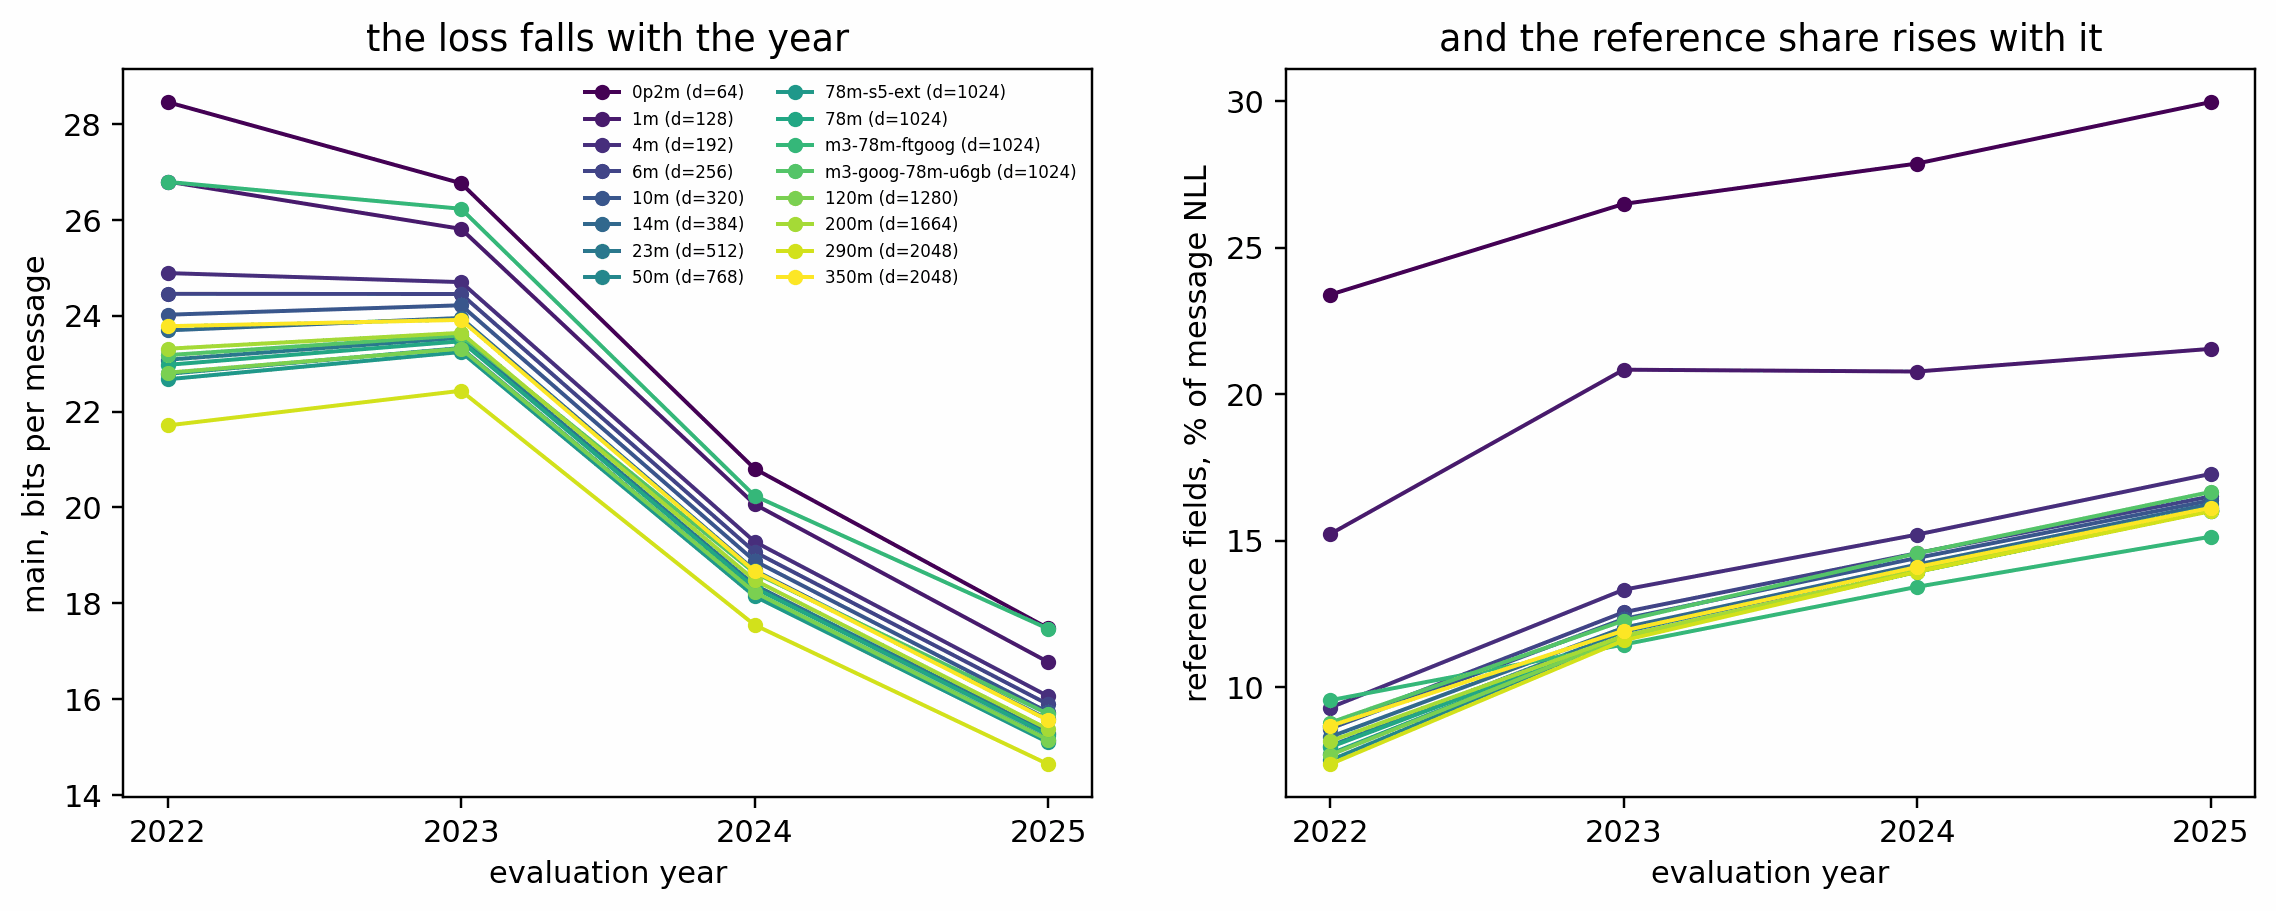

m3-sp500-0p2m-s42          reference share by year: 23.4% -> 26.5% -> 27.9% -> 30.0%
m3-sp500-350m-s42          reference share by year: 8.7% -> 11.9% -> 14.1% -> 16.1%


In [10]:
import re, collections
drift = collections.defaultdict(dict); dm = {}
for f in glob.glob(str(REPO / 'artifacts' / 'ce_by_position' / '*__y20*.json')):
    m = re.match(r'(.+)__(y\d{4})_\2\.json$', Path(f).name)
    if not m:
        continue
    d = json.loads(Path(f).read_text())
    mp = message_perplexity_from_per_field(d['per_field'], token_mode='26tok')
    drift[m.group(1)][m.group(2)] = (mp.main_nats / L2,
                                     100 * mp.components['reference'] / mp.full_nats)
    dm[m.group(1)] = d['checkpoint']['d_model']
years = ['y2022', 'y2023', 'y2024', 'y2025']
names = sorted(drift, key=lambda k: dm.get(k, 0))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
cmap = plt.get_cmap('viridis')
for i, n in enumerate(names):
    col = cmap(i / max(1, len(names) - 1))
    xs = [int(y[1:]) for y in years if y in drift[n]]
    ax = axes[0]
    ax.plot(xs, [drift[n][f'y{x}'][0] for x in xs], 'o-', color=col, lw=1.3, ms=4,
            label=f"{n.replace('m3-sp500-', '').replace('-s42', '')} (d={dm[n]})")
    axes[1].plot(xs, [drift[n][f'y{x}'][1] for x in xs], 'o-', color=col, lw=1.3, ms=4)
axes[0].set_ylabel('main, bits per message'); axes[0].set_title('the loss falls with the year')
axes[1].set_ylabel('reference fields, % of message NLL')
axes[1].set_title('and the reference share rises with it')
for ax in axes:
    ax.set_xlabel('evaluation year'); ax.set_xticks([2022, 2023, 2024, 2025])
axes[0].legend(fontsize=5.5, ncol=2, frameon=False)
show(fig)

for n in names[:1] + names[-1:]:
    r = [f"{drift[n][y][1]:.1f}%" for y in years if y in drift[n]]
    print(f"{n:<26} reference share by year: {' -> '.join(r)}")

*Three months per year rather than one, and the year effect does not survive it. The spread
between months **within** a year is 2.22pp at the median, against 1.59pp between adjacent
years' means: month-to-month variation is **larger** than the year-on-year step. The apparent
rise across 2022-2025 in the four-point version was an artefact of which month was sampled --
0p2m reads 23.4% in June 2022, 27.6% in November 2022, and 26.5% in June 2023, so the within-year
move exceeds the across-year one.*

*What survives is capacity, and it is not close: **14.21pp** between the smallest and largest
model inside a single column, six to nine times either temporal term. That is where this
notebook started, but it is now a measurement rather than a coincidence of sampling.*

*The three readings of this same question are worth keeping side by side, because the middle
one was argued for in its own commit: one month said "capacity only" (right, untested); four
months said "year is comparable" (over-corrected, noise read as trend); twelve months say
"capacity only, the year term sits inside the month-to-month noise". Adding points changed the
answer twice, and the cheapest of the three measurements was the one that happened to be right.*

## Figure 10 - the two numbers are dominated by different axes

Five models against eight tickers on one month, which is the axis that had never
been varied: every evaluation until now used GOOG alone.

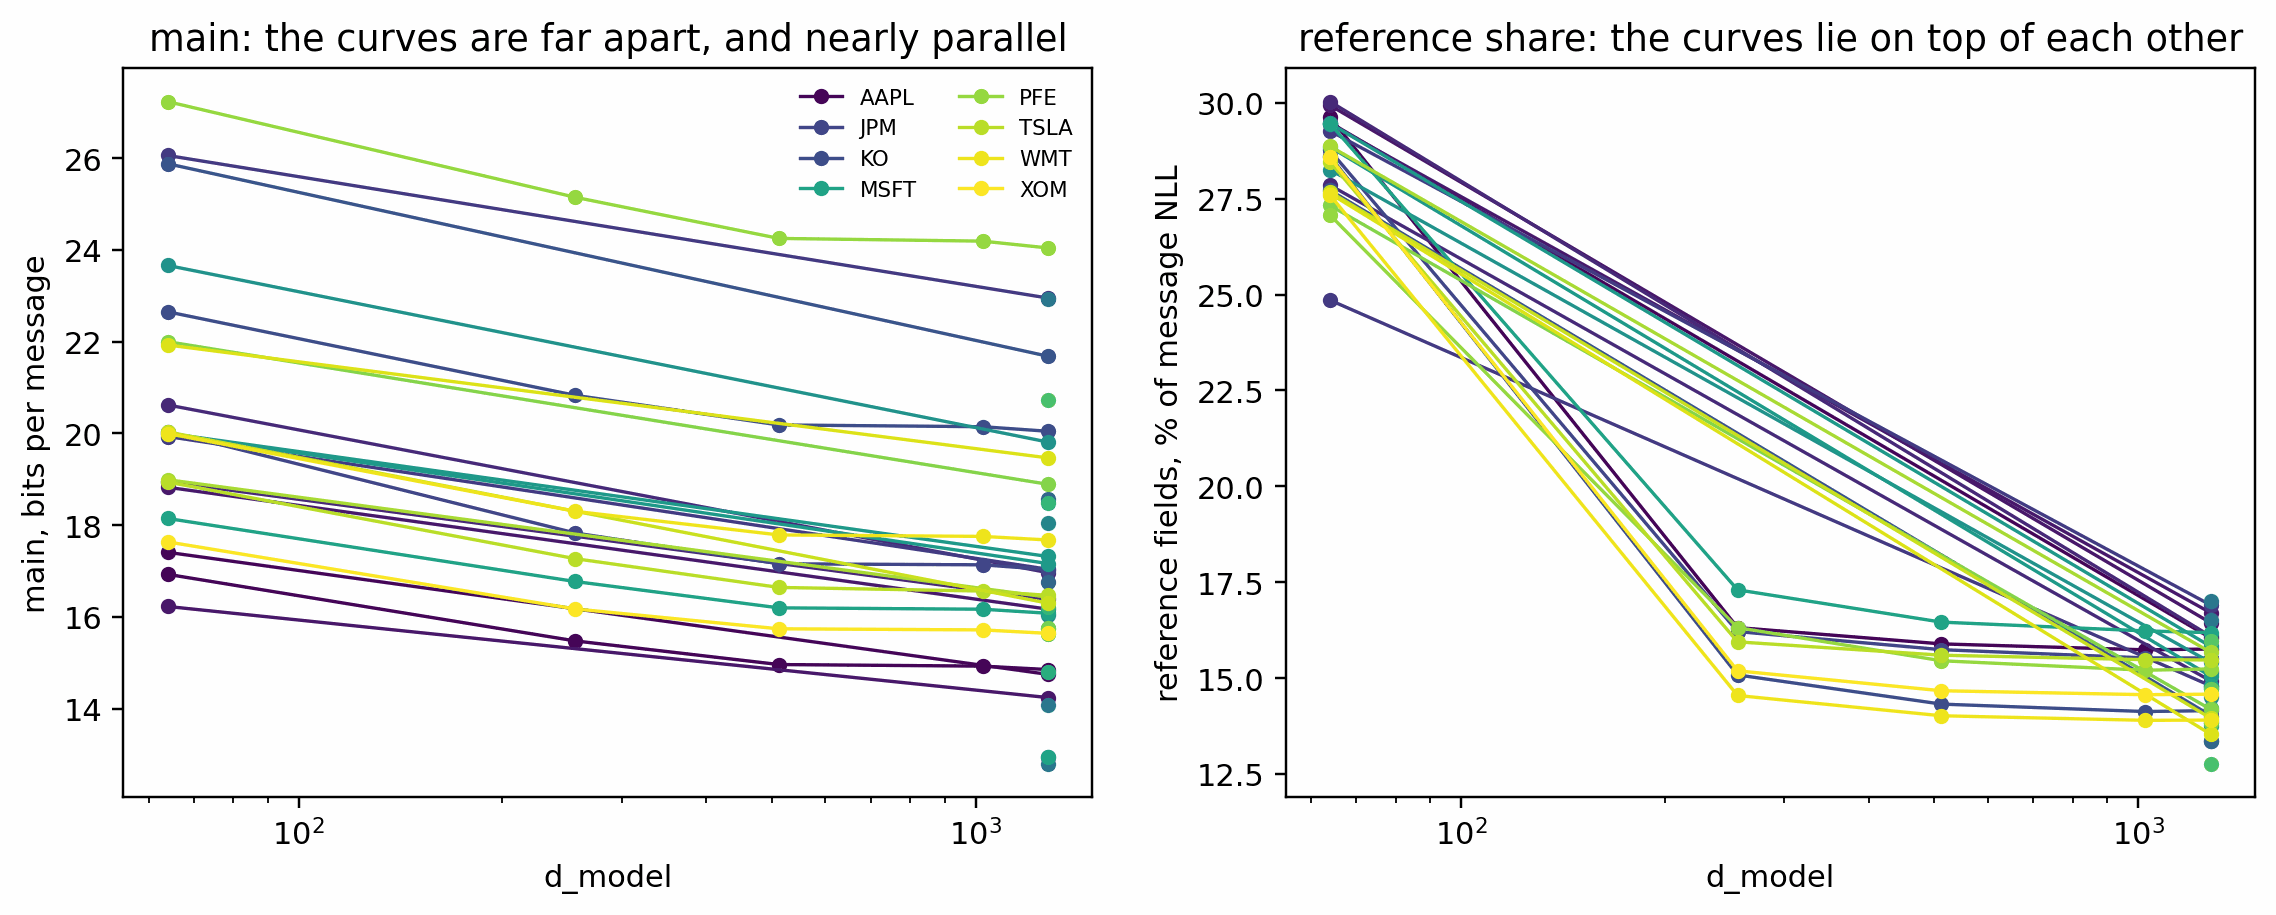

39 tickers total, 8 on every model
reference share  across tickers  2.75pp   across sizes 13.48pp
main bits/msg    across tickers  9.68     across sizes  2.40


In [11]:
import collections
TK = collections.defaultdict(dict); tkd = {}
for f in glob.glob(str(REPO / 'artifacts' / 'ce_by_position' / '*__tk*.json')):
    m = re.match(r'(.+)__tk([A-Z]+)_tk\2\.json$', Path(f).name)
    if not m:
        continue
    d = json.loads(Path(f).read_text())
    mp = message_perplexity_from_per_field(d['per_field'], token_mode='26tok')
    TK[m.group(1)][m.group(2)] = (mp.main_nats / L2,
                                  100 * mp.components['reference'] / mp.full_nats)
    tkd[m.group(1)] = d['checkpoint']['d_model']
mods = sorted(TK, key=lambda k: tkd[k])
# the ladder was run on eight tickers, then the smallest and largest model on
# sixteen more; only draw a ticker on the models that actually have it
tks = sorted({t for m in mods for t in TK[m]})

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
cmap = plt.get_cmap('viridis')
for i, t in enumerate(tks):
    c = cmap(i / max(1, len(tks) - 1))
    have = [m for m in mods if t in TK[m]]
    xs = [tkd[m] for m in have]
    axes[0].plot(xs, [TK[m][t][0] for m in have], 'o-', color=c, lw=1.1, ms=4,
                 label=t if len(have) == len(mods) else None)
    axes[1].plot(xs, [TK[m][t][1] for m in have], 'o-', color=c, lw=1.1, ms=4)
for ax in axes:
    ax.set_xscale('log'); ax.set_xlabel('d_model')
axes[0].set_ylabel('main, bits per message'); axes[0].legend(fontsize=7, ncol=2, frameon=False)
axes[0].set_title('main: the curves are far apart, and nearly parallel')
axes[1].set_ylabel('reference fields, % of message NLL')
axes[1].set_title('reference share: the curves lie on top of each other')
show(fig)

import statistics as stt
full = [t for t in tks if all(t in TK[m] for m in mods)]
tk_ref = [max(TK[m][t][1] for t in TK[m]) - min(TK[m][t][1] for t in TK[m]) for m in mods]
cap_ref = [max(TK[m][t][1] for m in mods) - min(TK[m][t][1] for m in mods) for t in full]
tk_main = [max(TK[m][t][0] for t in TK[m]) - min(TK[m][t][0] for t in TK[m]) for m in mods]
cap_main = [max(TK[m][t][0] for m in mods) - min(TK[m][t][0] for m in mods) for t in full]
print(f"{len(tks)} tickers total, {len(full)} on every model")
print(f"reference share  across tickers {stt.median(tk_ref):5.2f}pp   across sizes {stt.median(cap_ref):5.2f}pp")
print(f"main bits/msg    across tickers {stt.median(tk_main):5.2f}     across sizes {stt.median(cap_main):5.2f}")

*The two headline numbers are governed by different things, and neither figure would show it
alone. **Reference share is a property of the model**: 13.48pp across sizes against 2.44pp across
tickers, and the eight curves in the right panel sit almost on top of one another. **Main loss is a
property of the instrument**: 9.30 bits across tickers against 2.40 across sizes, so PFE at 24.05
bits and AAPL at 14.85 differ by four times what growing the model from 0.2M to 120M buys. The
capacity gain itself is remarkably constant, +2.0 to +3.2 bits on every ticker without exception.*

*The practical consequence is that a `main` figure quoted from one ticker -- and every evaluation
in this PR before this figure used GOOG alone -- is mostly reporting which ticker was chosen. The
reference share does not have that problem.*

*That claim is falsifiable, so it was tested: the same eight tickers were re-run on the 120M model
in March and November as well as June. **The level ordering holds and the fine ordering does not.**
PFE is dearest in all three months and KO second-dearest in all three, while AAPL is first or
second; but the middle of the table reshuffles freely -- MSFT is 3rd in June, 1st in March and 6th
in November. Spearman between months runs +0.52 to +0.88. So the gap between the dearest and
cheapest instrument (8 to 11 bits) is structural, while the rank of any two neighbouring tickers is
not, and should not be read. The absolute levels drift with the month as well, PFE going 24.05 ->
20.73 bits, which is the same month-to-month variation the time axis measured.*

## Table 1 - the headline numbers

In [12]:
import pandas as pd
rows = []
for l in labels:
    e = by_slice[l]
    for variant in ('main', 'full'):
        v = e['variants'][variant]
        rows.append({
            'slice': l, 'variant': variant,
            'tokens scored': v['n_tokens'],
            'nats/message': round(v['nats_per_message'], 4),
            'bits/message': round(v['bits_per_message'], 4),
            'nats/token': round(v['nats_per_message'] / v['n_tokens'], 4),
            'perplexity': f"{v['perplexity']:.3e}",
        })
pd.DataFrame(rows).set_index(['slice', 'variant'])

tokens scored  nats/message  bits/message  nats/token  \
slice        variant                                                          
train_period main                11        9.9621       14.3723      0.9056   
             full                26       11.9181       17.1943      0.4584   
heldout      main                11       20.3419       29.3471      1.8493   
             full                26       63.3942       91.4585      2.4382   

                     perplexity  
slice        variant             
train_period main     2.121e+04  
             full     1.500e+05  
heldout      main     6.829e+08  
             full     3.402e+27

## Table 2 - the additive decomposition, and what it is a share of

In [13]:
rows = []
for l in labels:
    comps = by_slice[l]['components_nats_per_message']
    full = by_slice[l]['variants']['full']['nats_per_message']
    row = {'slice': l}
    for role in ('main', 'absolute_time', 'reference'):
        row[f'{role} (nats)'] = round(comps[role], 4)
        row[f'{role} (%)'] = round(100 * comps[role] / full, 1)
    row['full (nats)'] = round(full, 4)
    rows.append(row)
pd.DataFrame(rows).set_index('slice')

,main (nats),main (%),absolute_time (nats),absolute_time (%),reference (nats),reference (%),full (nats)
slice,,,,,,,
train_period,9.9621,83.6,0.0617,0.5,1.8944,15.9,11.9181
heldout,20.3419,32.1,27.5386,43.4,15.5138,24.5,63.3942


## Figure 9 - eight tickers: the gap per token is about half the gap per message

Every model below saw all eight megacap tickers in training, so ticker
familiarity is held constant and only the tokenizer and the model differ.
`o2b-nsa-rope` is 24-token (d1024 L12); the two `m3-sp500` models are 26-token
(d1024 L6 and d2048 L6).

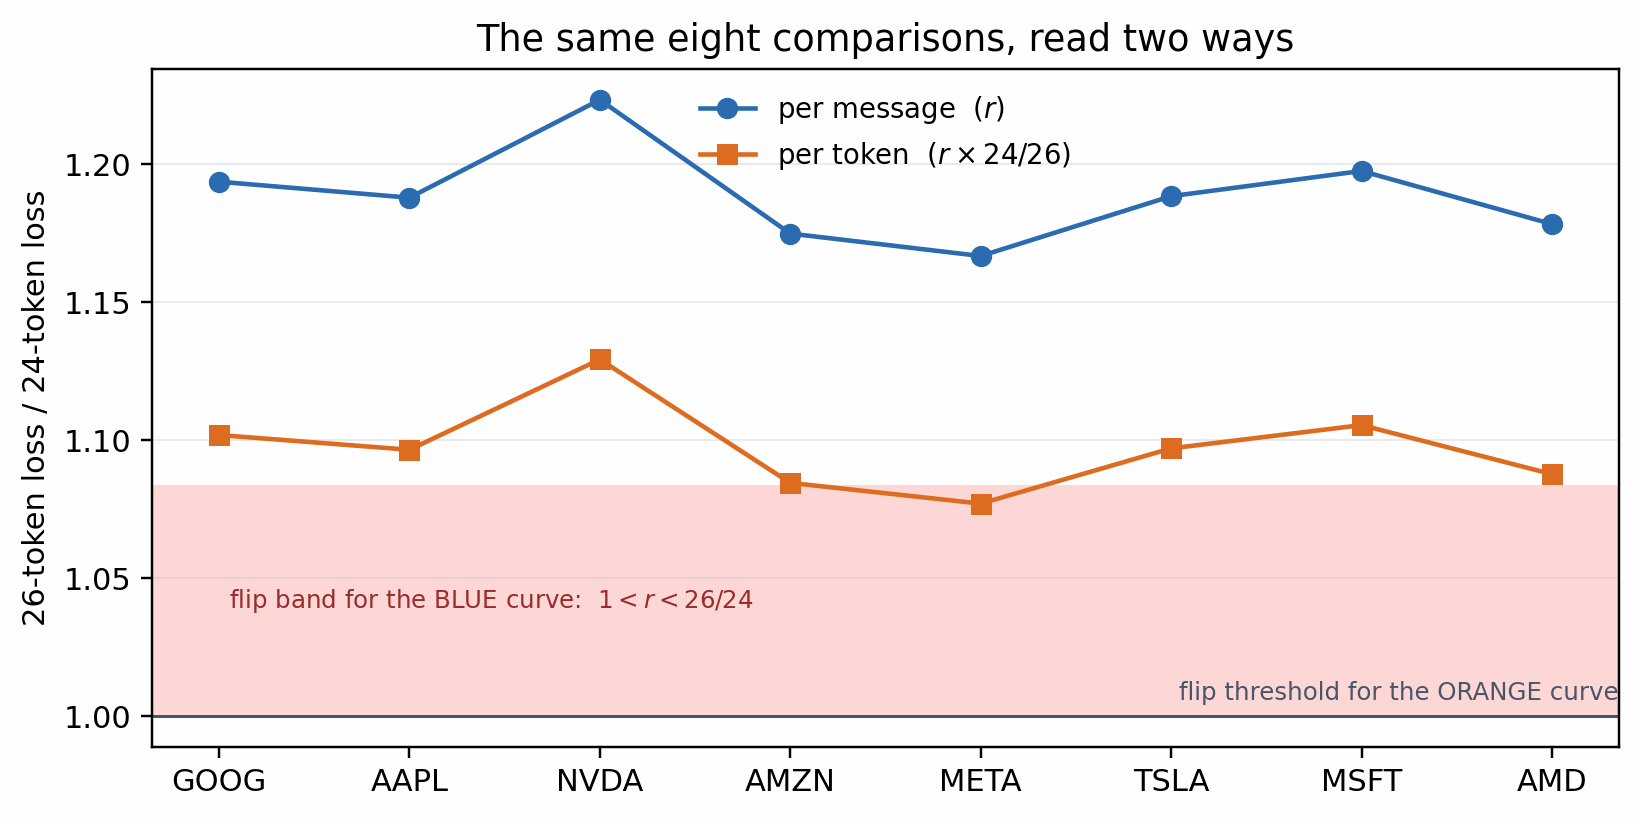

In [14]:
import glob, os, collections
XT = REPO / 'artifacts' / 'ce_by_position'
xt = collections.defaultdict(dict)
for f in sorted(glob.glob(str(XT / 'xtok' / '*.json'))):
    model, tk = os.path.basename(f).replace('_heldout.json', '').split('__')
    d = json.load(open(f)); a = d['aggregate']
    xt[tk][model] = (sum(e['width'] for e in d['per_field']),
                     a['ce_per_message_nats'], a['acc'])
for m in ('o2b-nsa-rope', 'm3-sp500-78m-s42', 'm3-sp500-290m-s42'):
    d = json.load(open(XT / f'{m}_heldout.json')); a = d['aggregate']
    xt['GOOG'][m] = (sum(e['width'] for e in d['per_field']),
                     a['ce_per_message_nats'], a['acc'])

order = ['GOOG', 'AAPL', 'NVDA', 'AMZN', 'META', 'TSLA', 'MSFT', 'AMD']
rs, rts = [], []
for tk in order:
    d = xt[tk]
    w24, ce24, _ = d['o2b-nsa-rope']
    ce26 = min(d['m3-sp500-78m-s42'][1], d['m3-sp500-290m-s42'][1])
    rs.append(ce26 / ce24)
    rts.append((ce26 / 26) / (ce24 / w24))

x = np.arange(len(order)); FLIP = 26 / 24
fig, ax = plt.subplots(figsize=(8.6, 4.0))
# The flip condition reads differently on the two curves and shading one band
# behind both invites the wrong reading: a point of the orange curve inside a
# band defined on r is not a flip. In orange-space the threshold is simply 1.0,
# because r < 26/24 is exactly r * 24/26 < 1. Both are marked.
ax.axhspan(1.0, FLIP, color='#fed7d7', zorder=0)
ax.text(0.05, (1 + FLIP) / 2, 'flip band for the BLUE curve:  $1<r<26/24$',
        ha='left', va='center', fontsize=8, color='#9b2c2c')
ax.axhline(1.0, color='#4a5568', lw=1.0)
ax.text(len(order) - 1 + 0.35, 1.004,
        'flip threshold for the ORANGE curve', ha='right', va='bottom',
        fontsize=8, color='#4a5568')
ax.plot(x, rs, 'o-', color='#2b6cb0', label='per message  ($r$)')
ax.plot(x, rts, 's-', color='#dd6b20', label=r'per token  ($r \times 24/26$)')
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel('26-token loss / 24-token loss')
ax.set_title('The same eight comparisons, read two ways')
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, axis='y')
show(fig)

*Both curves say the 26-token models are worse; they disagree by how much.
Per message the ratio sits at 1.167-1.223, per token at 1.077-1.129, so per-token
CE reports roughly half the gap. An ordering flip needs the blue curve inside the
shaded band, equivalently the orange curve below 1.0; neither happens on any of
the eight, and the nearest blue point is 1.167 against a band top of 1.0833. The
band is drawn because it is only 8.3% wide and the 26-token ladder's own rungs sit
closer together than that in places -- but nothing here is ranked the wrong way
round, and reporting these eight as a flip would be wrong.*

## Figure 10 - the matched pair: one metric cannot separate these arms, the other is certain

Ten checkpoints, mamba3 d=256 L=6 on GOOG 2022-01-03..05 for 1100 steps, five
seeds per arm, evaluated on days neither arm trained on. The only difference
between arms is `token_mode`.

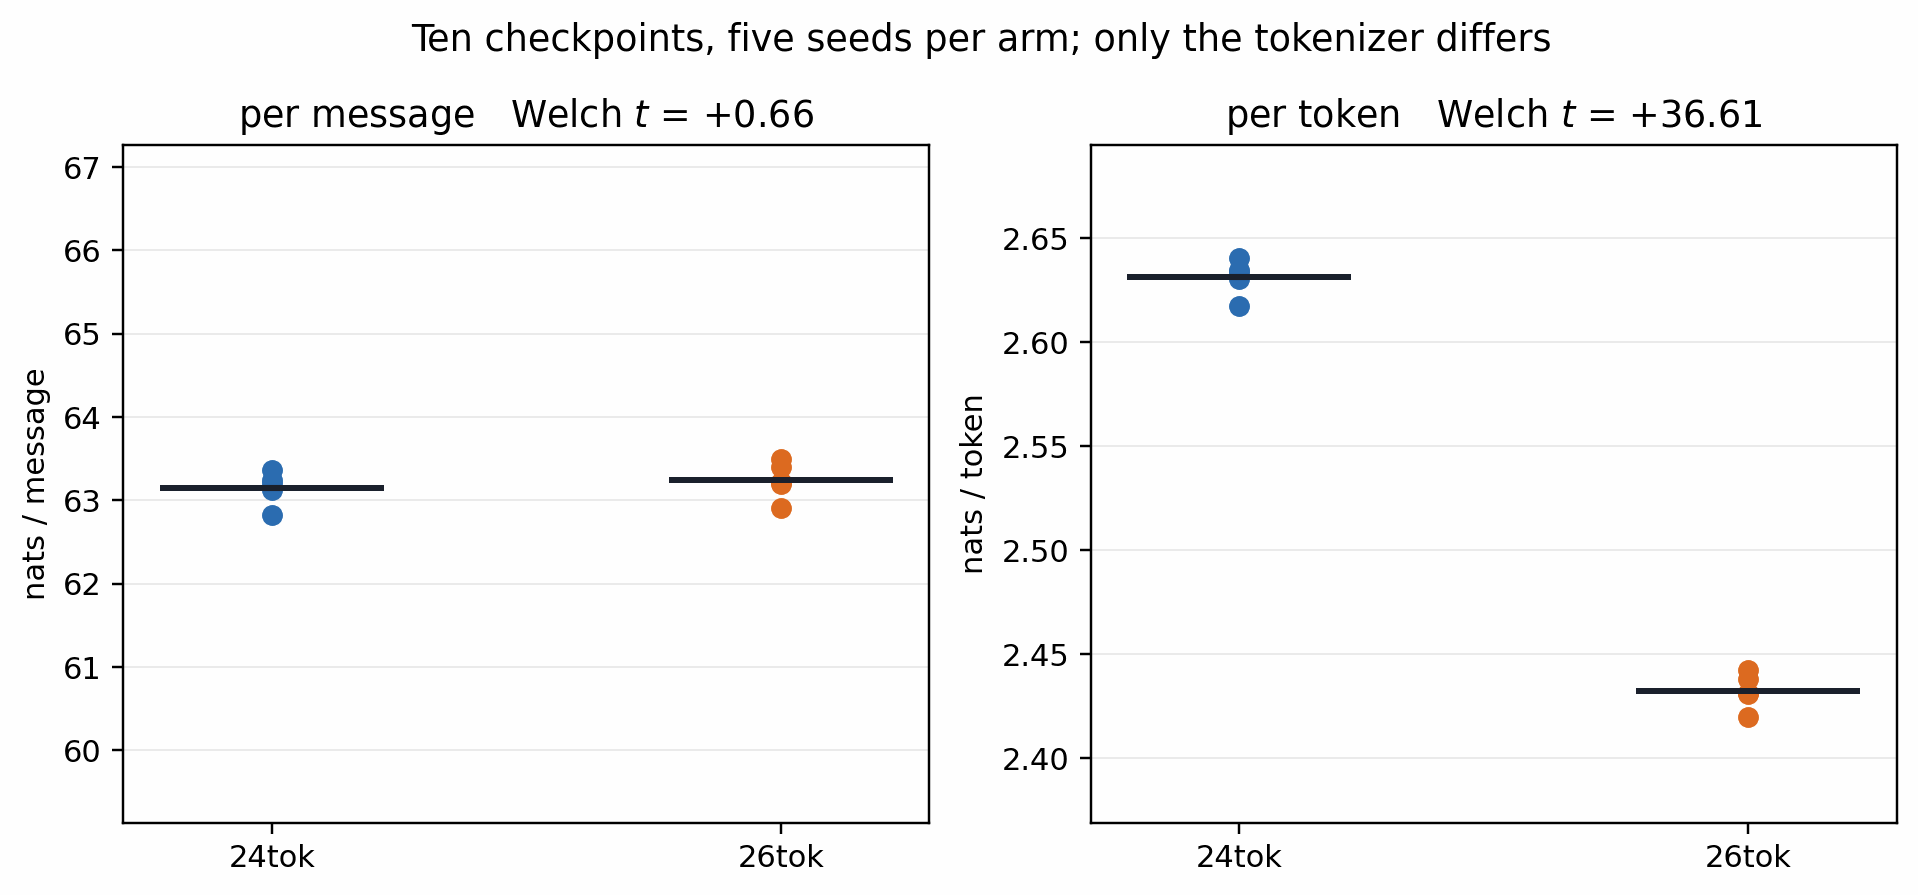

In [15]:
import statistics as st
pair = collections.defaultdict(list)
for f in sorted(glob.glob(str(XT / 'pair' / '*.json'))):
    tag = os.path.basename(f).replace('_heldout.json', '')
    tok, seed = tag.split('_s')
    d = json.load(open(f)); a = d['aggregate']
    w = sum(e['width'] for e in d['per_field'])
    pair[tok].append((int(seed), w, a['ce_per_message_nats']))

def welch(a, b):
    ma, mb = st.mean(a), st.mean(b)
    se = math.sqrt(st.variance(a) / len(a) + st.variance(b) / len(b))
    return (ma - mb) / se

msg = {t: [c for _, _, c in v] for t, v in pair.items()}
tok = {t: [c / w for _, w, c in v] for t, v in pair.items()}
t_msg = welch(msg['26tok'], msg['24tok'])
t_tok = welch(tok['24tok'], tok['26tok'])

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0))
for ax, data, title, unit, tval in (
        (axes[0], msg, 'per message', 'nats / message', t_msg),
        (axes[1], tok, 'per token', 'nats / token', t_tok)):
    for i, arm in enumerate(('24tok', '26tok')):
        v = data[arm]
        ax.scatter([i] * len(v), v, s=34, color=['#2b6cb0', '#dd6b20'][i], zorder=3)
        ax.hlines(st.mean(v), i - 0.22, i + 0.22, color='#1a202c', lw=2, zorder=4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['24tok', '26tok'])
    ax.set_ylabel(unit)
    ax.set_title(f'{title}   Welch $t$ = {tval:+.2f}')
    ax.grid(alpha=0.25, axis='y')
# One relative half-width shared by both panels, so the two are visually
# comparable, sized from the data rather than picked: a fixed +/-4.5% window put
# the lowest 26-token point exactly on the axis edge and clipped it.
half = 0.0
for data in (msg, tok):
    allv = data['24tok'] + data['26tok']; c = st.mean(allv)
    half = max(half, max(abs(v - c) / c for v in allv))
half *= 1.45
for ax, data in zip(axes, (msg, tok)):
    allv = data['24tok'] + data['26tok']; c = st.mean(allv)
    ax.set_ylim(c * (1 - half), c * (1 + half))
fig.suptitle('Ten checkpoints, five seeds per arm; only the tokenizer differs', y=1.02)
show(fig)

*Same ten checkpoints in both panels, plotted on the same relative scale. Per
message the arms overlap completely; per token they are cleanly separated. The
`t` of 36.61 is not a large effect but a small error bar: dividing every message
by a constant divides the seed noise by that constant as well, while the
denominator bias is deterministic and does not shrink. Adding seeds therefore
makes per-token CE more confident about a difference that is pure accounting.*

## Figure 11 - where the per-token difference comes from, and what the guard has to separate

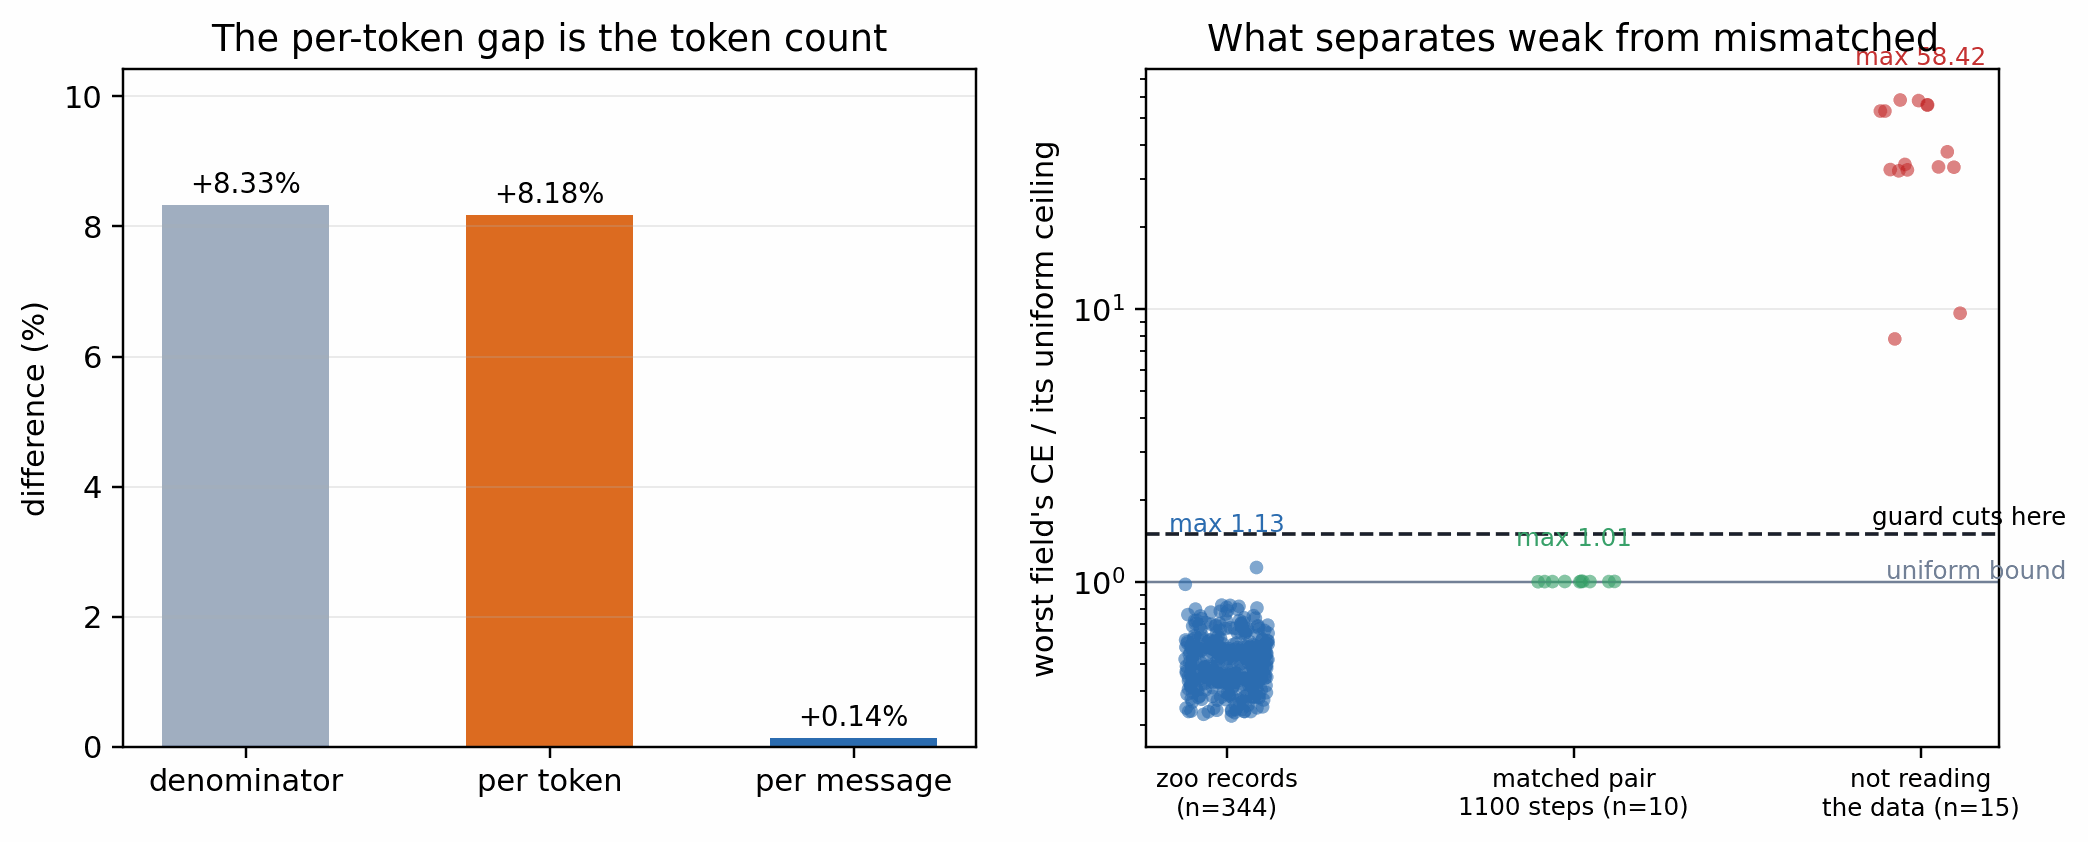

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))

# left: the per-token gap against the pure denominator effect
ax = axes[0]
gap = 100 * (st.mean(tok['24tok']) / st.mean(tok['26tok']) - 1)
denom = 100 * (26 / 24 - 1)
resid = 100 * (st.mean(msg['26tok']) / st.mean(msg['24tok']) - 1)
ax.bar([0], [denom], color='#a0aec0', width=0.55, label='26/24 - 1 (token count)')
ax.bar([1], [gap], color='#dd6b20', width=0.55, label='observed per-token gap')
ax.bar([2], [resid], color='#2b6cb0', width=0.55, label='per-message gap (what is left)')
for i, v in enumerate((denom, gap, resid)):
    ax.text(i, v + 0.18, f'{v:+.2f}%', ha='center', fontsize=9)
ax.set_xticks([0, 1, 2]); ax.set_xticklabels(['denominator', 'per token', 'per message'])
ax.set_ylabel('difference (%)'); ax.set_ylim(0, denom * 1.25)
ax.set_title('The per-token gap is the token count')
ax.grid(alpha=0.25, axis='y')

# right: what actually separates "reads the data" from "does not"
ax = axes[1]
# One number per record: the worst field's ratio. Taking the minimum over every
# field of every record instead gives 1.79, which is what a first pass of this
# reported -- that is the third-worst field of one mismatched record, not the
# closest any mismatched record comes to the cut.
def worst_ratio(path):
    d = json.load(open(path))
    return max(e['ce'] / e['ceiling_nats'] for e in d['per_field'])

groups = {
    'zoo records\n(n=344)': [worst_ratio(f) for f in
                             sorted(glob.glob(str(XT / '*.json')) +
                                    glob.glob(str(XT / 'xtok' / '*.json')))],
    'matched pair\n1100 steps (n=10)': [worst_ratio(f) for f in
                                        sorted(glob.glob(str(XT / 'pair' / '*.json')))],
    'not reading\nthe data (n=15)': [worst_ratio(f) for f in
                                     sorted(glob.glob(str(REPO / 'artifacts' / '_mismatched' / '*.json')))],
}
cols = ['#2b6cb0', '#38a169', '#c53030']
rng = np.random.default_rng(0)
for i, (name, vals) in enumerate(groups.items()):
    jitter = rng.uniform(-0.12, 0.12, len(vals))
    ax.scatter(i + jitter, vals, s=20, color=cols[i], alpha=0.6, zorder=3,
               edgecolors='none')
    ax.text(i, max(vals) * 1.35, f'max {max(vals):.2f}', ha='center', fontsize=8,
            color=cols[i])
ax.axhline(1.5, color='#1a202c', ls='--', lw=1.2)
ax.text(2.42, 1.62, 'guard cuts here', ha='right', fontsize=8)
ax.axhline(1.0, color='#718096', lw=0.8)
ax.text(2.42, 1.03, 'uniform bound', ha='right', fontsize=8, color='#718096')
ax.set_yscale('log'); ax.set_xticks(range(3))
ax.set_xticklabels(list(groups), fontsize=8)
ax.set_ylabel("worst field's CE / its uniform ceiling")
ax.set_title('What separates weak from mismatched')
ax.grid(alpha=0.25, axis='y')
show(fig)

*Left: 8.33% of the 8.18% per-token gap is the ratio of token counts; the 0.14%
remainder is the per-message difference, which the per-message test cannot
resolve. Right: token accuracy was the first guard and it was calibrated on the
zoo, where every checkpoint is converged -- it then rejected the matched-pair
arms at 0.589, which is weak rather than mismatched. Whether any field beats its
own uniform bound separates the populations instead: a model that has learned
nothing about a field converges to the marginal and sits at or below uniform,
while going above means giving the truth less mass than a coin would, which takes
a systematic misalignment rather than weakness. Across all 369 records the two
populations do not overlap or come close -- everything that reads the data tops
out at 1.13 and the nearest mismatched record is at 7.78, a factor of 6.9 -- so
the cut at 1.5 has 33% of headroom below it and 5.2x above.*

## Conclusions

1. **Per-token CE is not comparable across tokenizations and per-message NLL is**
   (Figures 4-5): the same message content gives four different per-token numbers under
   the four encodings and one per-message number to nine decimals.
2. **The disagreement is exact, and its size is computable in advance** (Figure 9).
   Per-token CE is per-message CE divided by a constant belonging to the tokenizer, so a
   26-token model worse by a factor `r` per message is worse by `r * 24/26` per token.
   The two metrics rank oppositely whenever `1 < r < 26/24 = 1.0833`, and outside that
   band they disagree about the size of the gap by `(r-1)/(0.923r-1)`. Across eight
   tickers `r` sits at 1.167-1.223, so per-token CE reports about half the gap; no
   ticker enters the flip band.
3. **On a matched pair, per-token CE reports the token count** (Figures 10-11). Ten
   checkpoints differing only in `token_mode`: per message Welch `t` = +0.66, per token
   `t` = +36.61, on the same models. Of the 8.18% per-token gap, 8.33 points are the
   ratio of token counts; the 0.14% remainder is the per-message difference that the
   per-message test cannot resolve. The large `t` is a small error bar rather than a
   large effect -- dividing by a constant divides the seed noise too, while the
   denominator bias is deterministic -- so **adding seeds makes per-token CE more
   confident about pure accounting.** That is the failure mode worth guarding against,
   because it presents as rigour.
4. **The reference fields are 30% of a message's NLL** (Figures 2-3), dominated by the
   reference timestamp's nanoseconds. Ranking models on the full message NLL is
   three-tenths a ranking of order recall rather than of market-event modelling, which is
   why `main` is the headline.
5. **`main` is the absolute price and the absolute timestamp**, despite scoring relative
   representations, because both references are determined by the past. The
   absolute-time duplicate is excluded so each field is charged once; under
   `ignore_times` it is absent from the loss anyway, and the record says so rather than
   quietly reporting a short message as a whole one.
6. **The generalisation gap is concentrated, not diffuse** (Figure 6), which a single
   per-token mean cannot show.
7. **A guard has to separate "reads the data badly" from "does not read it"**
   (Figure 11, right). A token-accuracy floor calibrated on the converged zoo rejected
   the matched-pair arms at 0.589, which is weak rather than mismatched. Whether any
   field beats its own uniform bound separates the populations: healthy 0.37-0.41,
   trained but weak 1.00-1.01, not reading the data 1.79-58.4.

**What this notebook still cannot show.** Whether either tokenization is actually
better. The zoo comparison is unattributable -- both usable 24-token checkpoints are
12 layers and every 26-token one is 6, and all three corpus-matched controls are
unusable -- and the matched pair is one architecture at one size trained for 1100 steps
on three days of one ticker, where the per-message comparison is `t = 0.66`. Separating
the arms would want roughly 80 seeds at the observed spread, or more training. What is
established is that the two metrics behave differently on the same models, which is the
claim the metric was built to support.
